# 第 8 章实验｜间隔、核与模型选择

用第2、6讲的 8×8 手写数字，从辨认 1 和 7 开始。先看两项图像特征，再比较直线和曲线，最后用全部 64 个像素识别十类数字。

沿用第6讲的划分，在 1,437 张开发图像内选参，再用 360 张预留图像报告测试表现。二分类实验使用其中的 289 张开发图像和 72 张预留图像。

核心 `fit`、预测和交叉验证（cross-validation）代码均在本 Notebook。辅助文件用于绘图和设置字体。课件定稿图用于对照；运行 Notebook 不会覆盖课件素材。数据划分与分层五折使用种子 42；从第一格开始执行，可在项目根目录或本文件目录运行。

In [1]:
from IPython.display import display, HTML, SVG
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('retina')
display(HTML("""<style>
.jp-Notebook .jp-RenderedMarkdown,.jp-Notebook .jp-OutputArea-output,
.jp-Notebook .jp-InputArea-editor,.jp-Notebook pre,.jp-Notebook table,
.rendered_html,.text_cell_render{font-size:20px!important;line-height:1.6}
.jp-Notebook img{max-width:100%;height:auto}
</style>"""))

In [2]:
from pathlib import Path
import sys, time, platform, warnings, importlib.metadata
from tempfile import TemporaryDirectory
import numpy as np
import pandas as pd
import sklearn
started = time.perf_counter()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'lessons/08-svm-kernels/notebook').is_dir())
NB_DIR = ROOT / 'lessons/08-svm-kernels/notebook'
sys.path.insert(0, str(NB_DIR))
from helpers import l8_plots as plot
from helpers.l8_plot_style import course_font_settings
slide_assets = NB_DIR.parent / "assets"
plot_output = TemporaryDirectory(prefix="lesson08-plots-")
plot.ASSETS = Path(plot_output.name)

def show_slide_figure(filename):
    display(SVG(filename=str(slide_assets / filename)))

In [3]:
from sklearn.datasets import load_digits
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures
from sklearn.metrics.pairwise import chi2_kernel, cosine_similarity, laplacian_kernel, rbf_kernel, sigmoid_kernel
from functools import partial
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

In [4]:
warning_log = []
original_showwarning = warnings.showwarning
def record_warning(message, category, filename, lineno, file=None, line=None):
    warning_log.append({'category': category.__name__, 'message': str(message)})
    original_showwarning(message, category, filename, lineno, file, line)
warnings.showwarning = record_warning
warnings.filterwarnings('error', category=ConvergenceWarning)
warnings.filterwarnings('error', message='Glyph .*missing.*')
versions = {p: importlib.metadata.version(p) for p in
            ['numpy', 'scipy', 'pandas', 'scikit-learn', 'matplotlib', 'nbclient', 'ipykernel']}
results = {'schema_version': '1.0', 'seeds': {'data':42, 'split':42, 'cv':42, 'models':42},
           'environment': {'python': sys.version, 'platform': platform.platform(), 'packages':versions,
                           'font':course_font_settings(), 'checked_date':'2026-10-28'}}
display(pd.Series(versions, name='版本'))

numpy            2.5.2
scipy           1.18.1
pandas           3.0.5
scikit-learn     1.9.0
matplotlib      3.11.1
nbclient        0.11.0
ipykernel        7.3.0
Name: 版本, dtype: str

## 1. 都能分对，余量一样吗？

用像素值除以 16 得到 0 至 1 的强度。左右不对称度是原图与镜像的逐像素绝对差均值。上部笔迹强度取前 3 行像素均值。

为了观察硬间隔，先从开发集中取不对称度小于 11% 的 1 和大于 18% 的 7，各按原始索引取前 6 张。这 12 张用于比较分界线，下图横排 6 对，每列上方是 1，下方是 7。

**先判断**：几条线都分对时，你会怎样选？

<!-- # [ref:l8-candidates] -->

In [5]:
digits = load_digits()
dev_ids, test_ids = train_test_split(np.arange(len(digits.target)), test_size=360,
    stratify=digits.target, random_state=42)
images = digits.images / 16
asymmetry = np.abs(images - images[:, :, ::-1]).mean(axis=(1, 2))
top_ink = images[:, :3, :].mean(axis=(1, 2))
features = np.c_[asymmetry, top_ink]
digit_ids = np.sort(dev_ids[np.isin(digits.target[dev_ids], [1, 7])])
Xd, yd = features[digit_ids], (digits.target[digit_ids] == 7).astype(int)
binary_test_ids = test_ids[np.isin(digits.target[test_ids], [1, 7])]
y_test = (digits.target[binary_test_ids] == 7).astype(int)

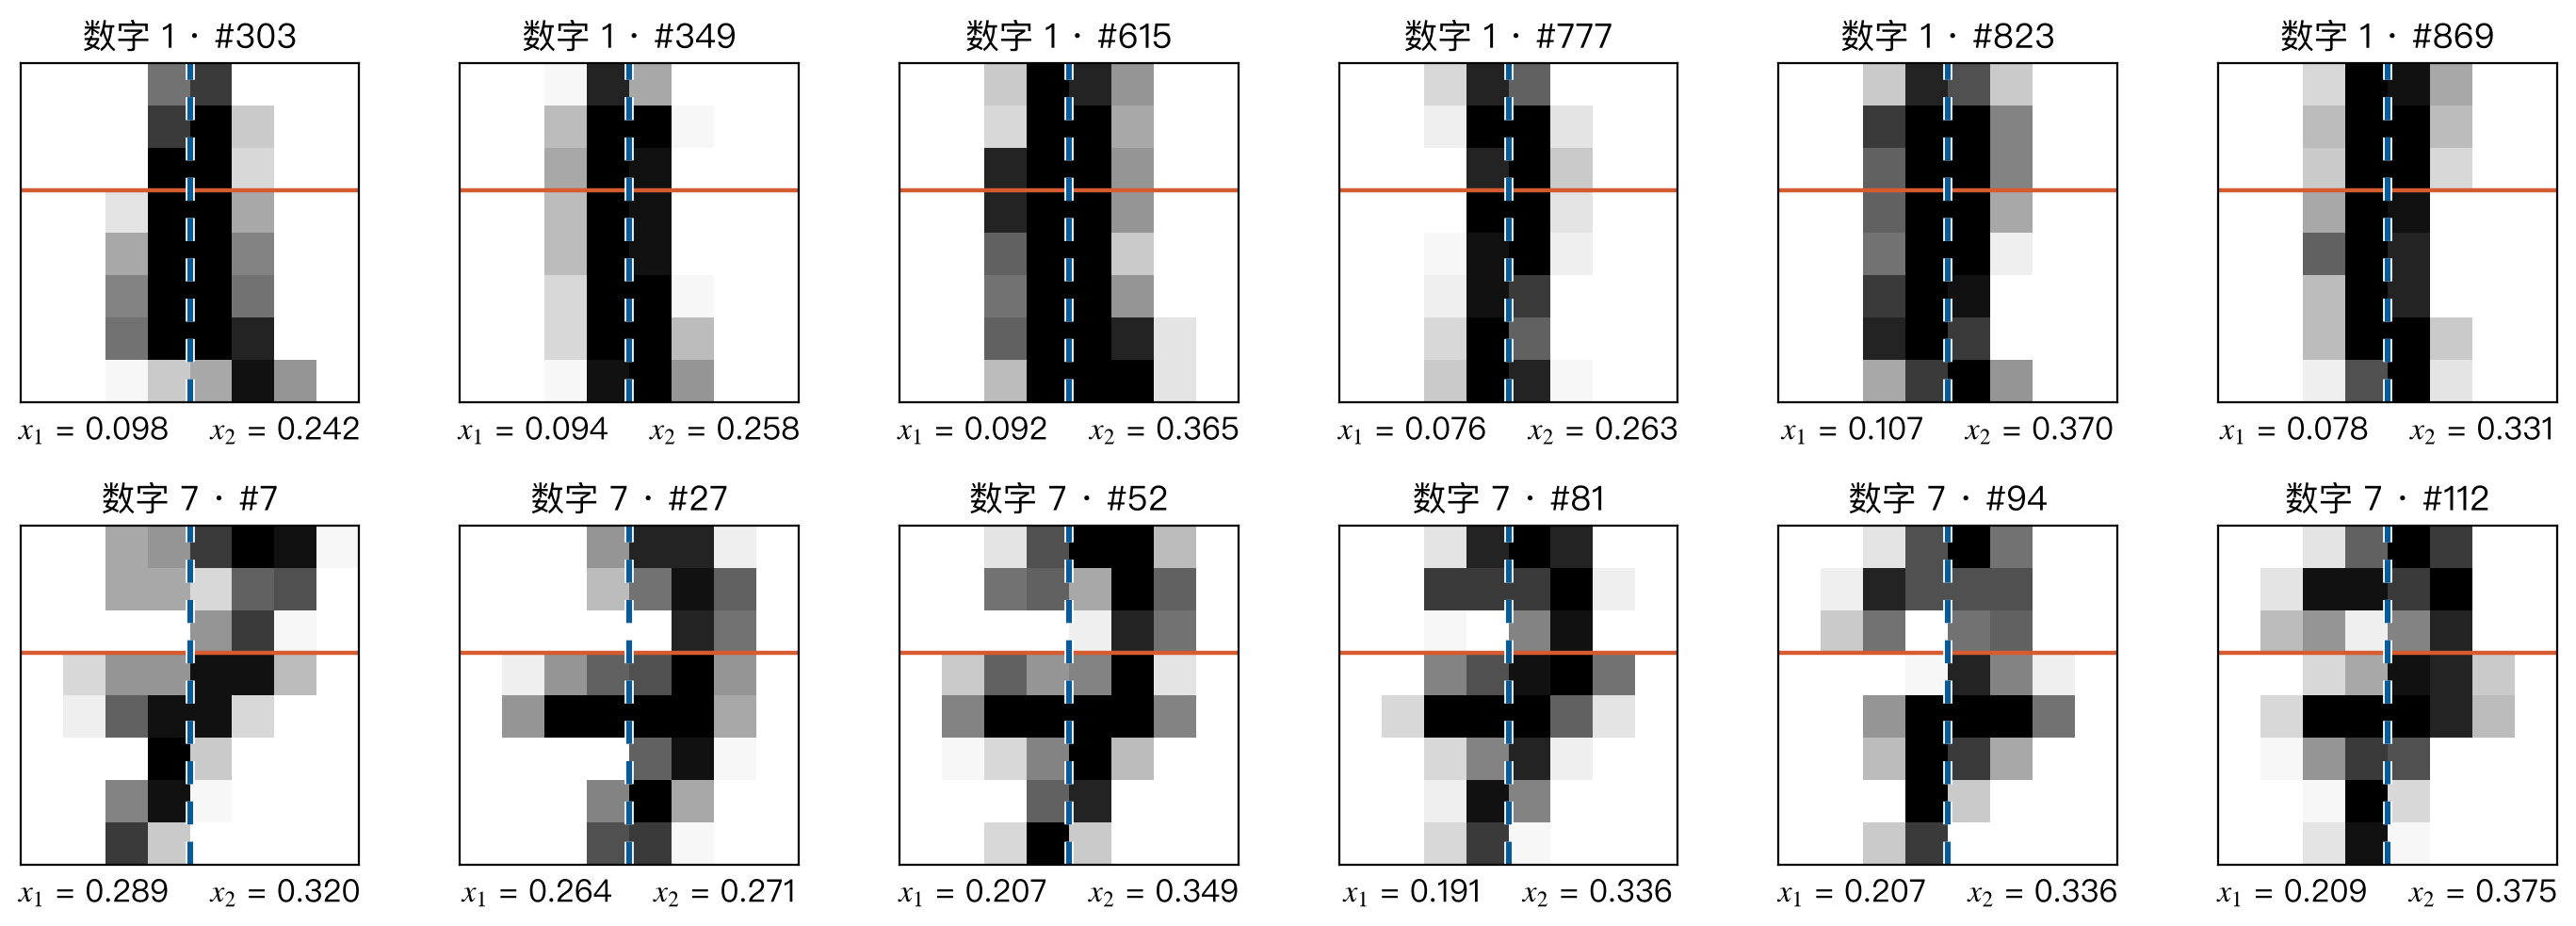

In [6]:
ones = digit_ids[(digits.target[digit_ids] == 1) & (asymmetry[digit_ids] < .11)]
sevens = digit_ids[(digits.target[digit_ids] == 7) & (asymmetry[digit_ids] > .18)]
demo_ids = np.r_[ones[:6], sevens[:6]]
X, y = features[demo_ids], (digits.target[demo_ids] == 7).astype(int)
shown_pairs = demo_ids.reshape(2, 6).T
plot.digit_features(images, features, shown_pairs, digits.target)
results['digits'] = {'dev_ids': dev_ids, 'binary_ids': digit_ids, 'demo_ids': demo_ids,
                     'counts': np.bincount(yd), 'features': features[digit_ids]}

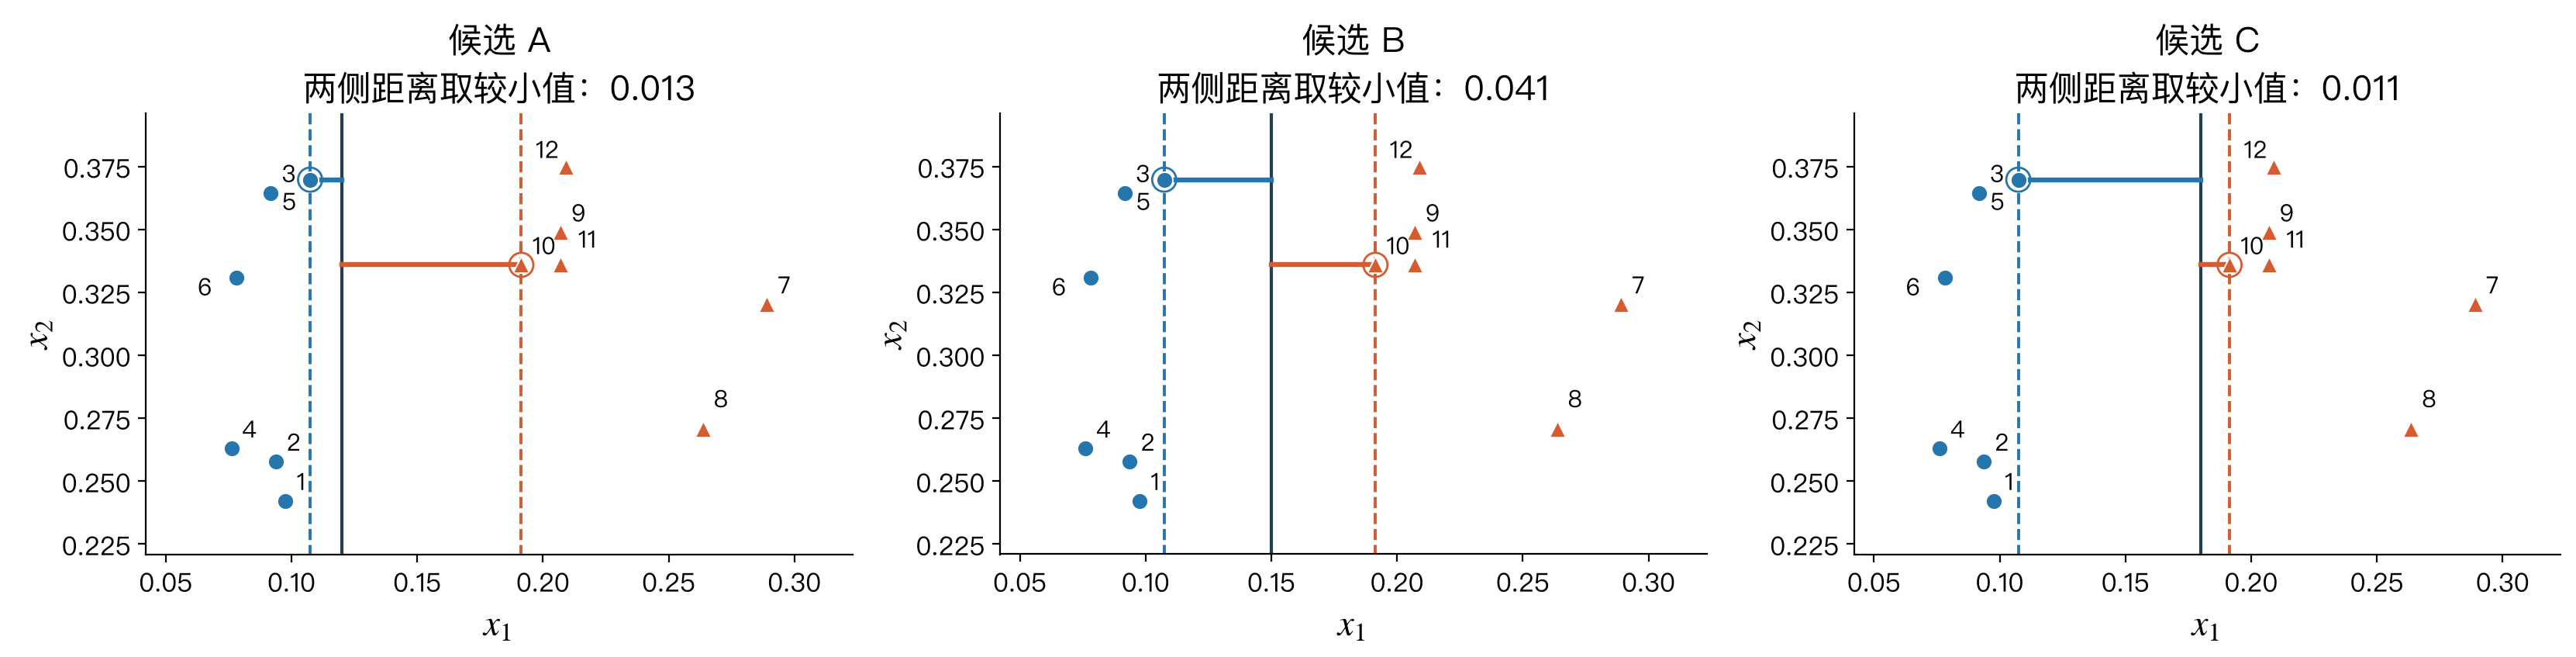

In [7]:
candidates = []
for name, w, b in [('候选 A', [1,0], -.12), ('候选 B', [1,0], -.15),
                   ('候选 C', [1,0], -.18)]:
    w = np.asarray(w, dtype=float)
    distances = np.abs(X @ w + b) / np.linalg.norm(w)
    candidates.append({'name':name, 'w':w, 'b':b,
        'min_distance':distances.min(), 'closest_index':int(distances.argmin()),
        'errors':int(np.sum((X @ w + b > 0) != y))})
assert all(row['errors'] == 0 for row in candidates), '候选线应全部分对'
results['candidate_lines'] = candidates
plot.candidate_plot(X, y, candidates)

## 2. 分类分数、间隔与支持向量（p4–p8）

线性分类器输出 $f(x)=w^Tx+b$，$w\in\mathbb R^2$，$b\in\mathbb R$。无符号距离是 $|f(x)|/\|w\|$。

在线性可分时，把最近点的带标签分数缩放到 1，单侧间隔就是 $1/\|w\|$。让这个距离最大，等价于在每条记录满足 $y_i f(x_i)\geq1$ 的条件下，让 $\frac12\|w\|^2$ 最小。

下面用较大的 `C=10000` 拟合干净数据，检查带标签分数是否接近或大于 1。这仍是软间隔 `SVC` API 的数值例子；没有调用独立硬间隔求解器。

**先判断**：把 $w,b$ 同乘 10，边界和点线距离会改变吗？

<!-- # [ref:l8-margin] -->

coef_ 形状： (1, 2) w： [23.10127478 -1.76795813] b： -2.8278059866226464
support_： [0 4 9] n_support_： [2 1]
单侧间隔： 0.04316144161418919 两侧总宽： 0.08632288322837837


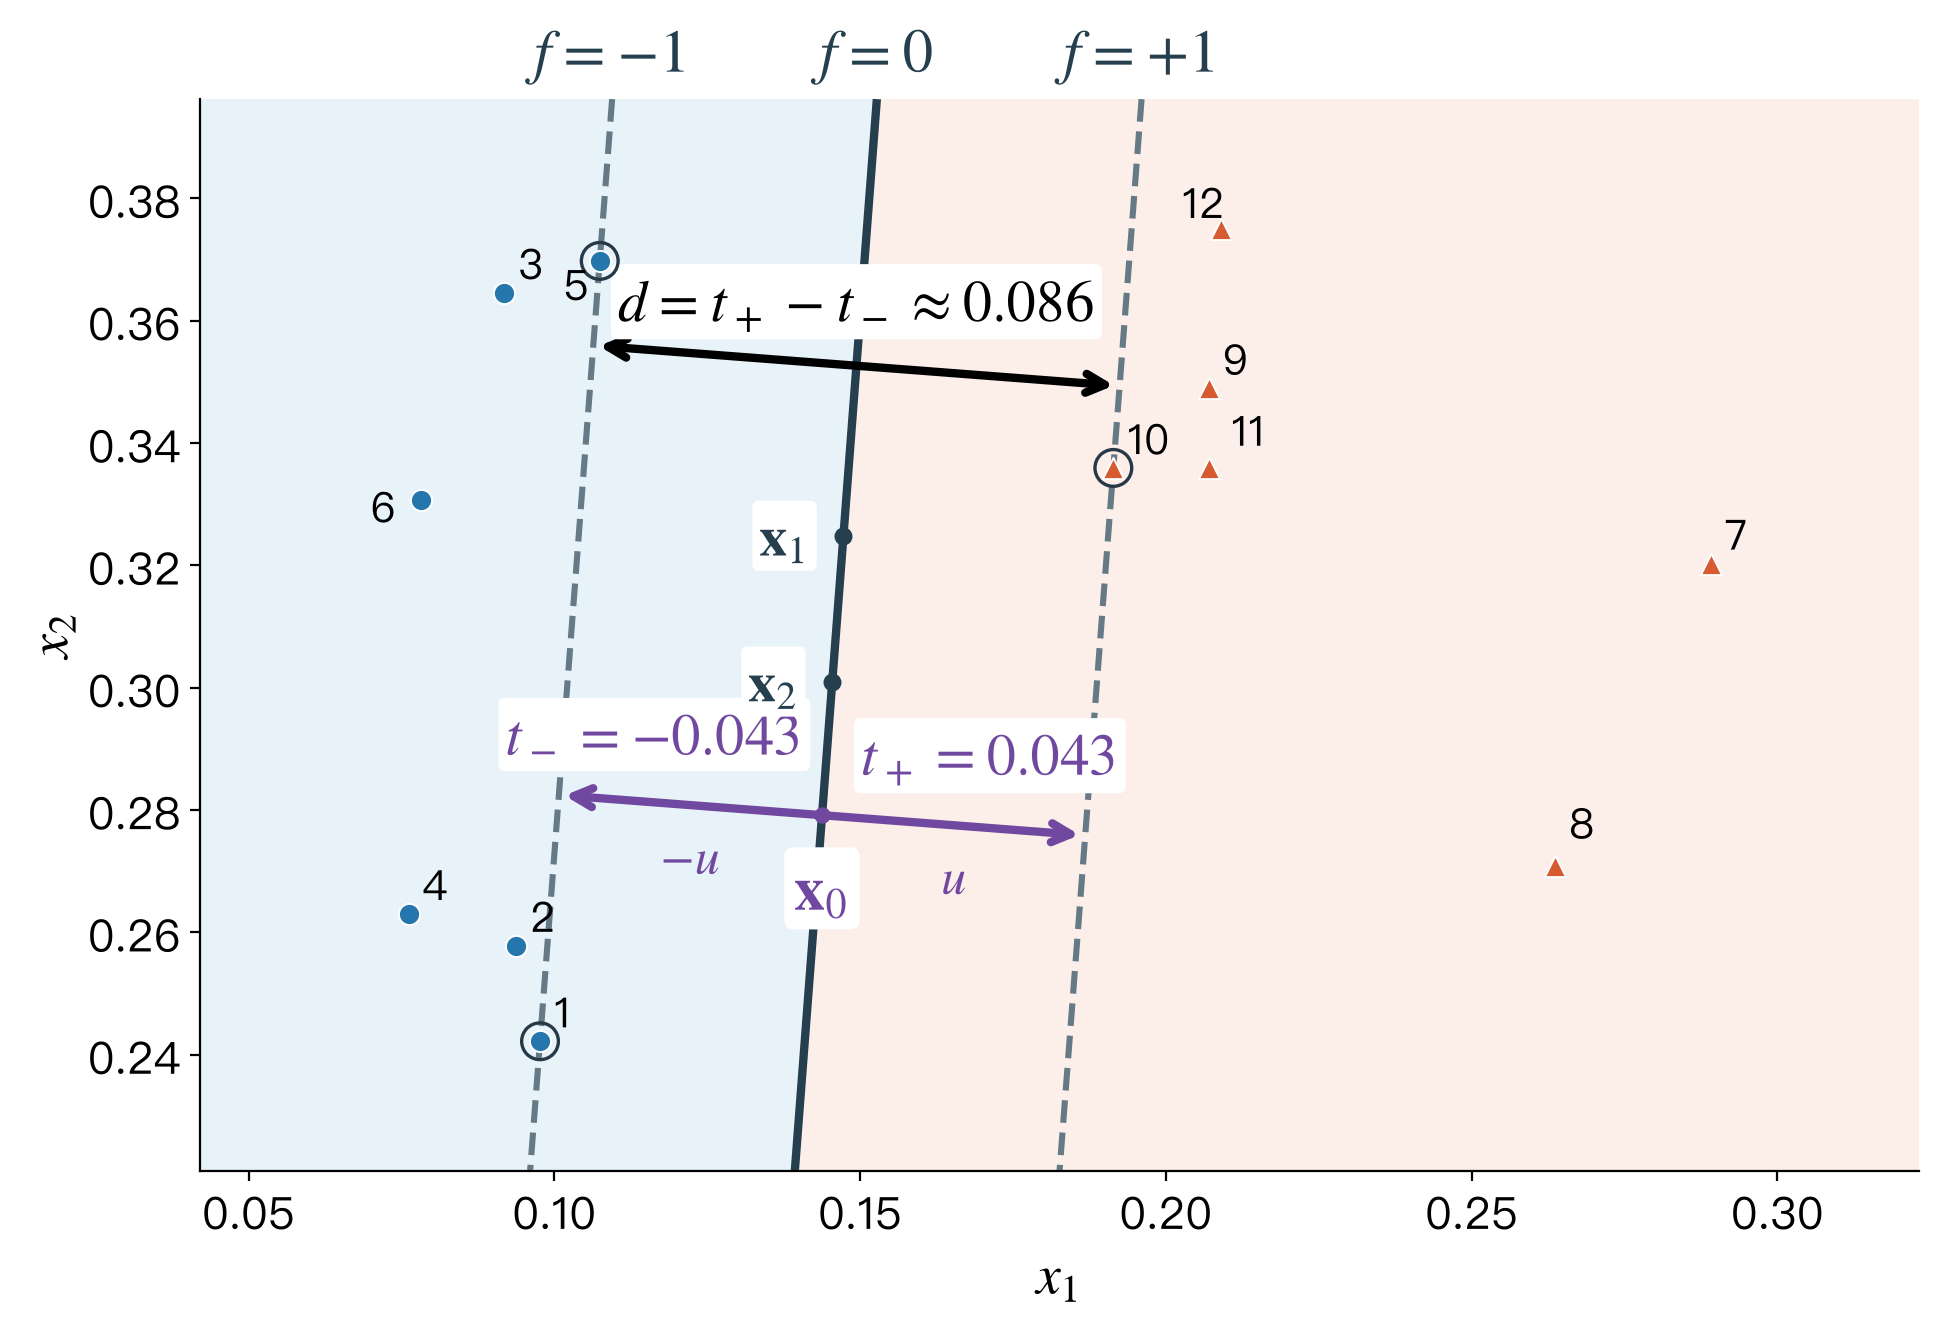

In [8]:
linear = SVC(kernel='linear', C=10000, tol=1e-8)
linear.fit(X, y)
w, b = linear.coef_[0], linear.intercept_[0]
results['margin'] = plot.linear_record(linear, X, y)
assert linear.score(X, y) == 1
assert np.min((2*y-1) * linear.decision_function(X)) >= 1-1e-5
print('coef_ 形状：', linear.coef_.shape, 'w：', w, 'b：', b)
print('support_：', linear.support_, 'n_support_：', linear.n_support_)
print('单侧间隔：', 1/np.linalg.norm(w), '两侧总宽：', 2/np.linalg.norm(w))
plot.margin_plot(X, y, linear)

### 硬间隔的可行域（p7）

分别从每个正类点与负类点得到截距的下限和上限。这里用这 36 对点直接构造权重约束，最小化 $\|w\|^2/2$。

约束数： 36 最优权重： [23.101 -1.768]
截距： -2.828


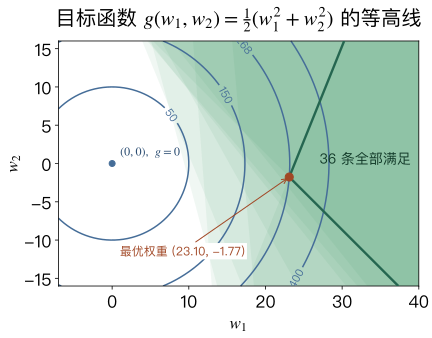

In [9]:
from scipy.optimize import LinearConstraint, minimize

differences = (X[y == 1, None] - X[y == 0]).reshape(-1, X.shape[1])
qp = minimize(lambda weights: (weights @ weights) / 2, np.zeros(X.shape[1]),
              jac=lambda weights: weights,
              constraints=LinearConstraint(differences, 2, np.inf), method='SLSQP')
assert qp.success, qp.message  # 确认求解器找到了可行解。
b_low = np.max(1 - X[y == 1] @ qp.x)
b_high = np.min(-1 - X[y == 0] @ qp.x)
print('约束数：', len(differences), '最优权重：', qp.x.round(3))
print('截距：', round((b_low + b_high) / 2, 3))
show_slide_figure('l8-qp-contours.svg')

### 哪些点约束了边界？

空心圈标记支持向量（support vector）。本例在原坐标拟合，无缩放器；删除样本时保持坐标与 `C` 固定。依次删去编号最小的一个非支持向量、编号最小的一个支持向量，各自复训。

**先判断**：删去支持向量后，边界一定移动吗？

<!-- # [ref:l8-support] -->

In [10]:
non_sv = int(np.setdiff1d(np.arange(len(X)), linear.support_)[0])
sv = int(linear.support_[0])
removed_models, removal_rows, remaining_supports = [], [], []
for kind, index in [('非支持向量', non_sv), ('支持向量', sv)]:
    keep = np.delete(np.arange(len(X)), index)
    fitted = SVC(kernel='linear', C=10000, tol=1e-8).fit(X[keep], y[keep])
    removed_models.append(fitted)
    remaining_supports.append(keep[fitted.support_])
    removal_rows.append({'kind':kind, 'removed_index':index, 'removed_point_id':index+1,
        'remaining_indices':keep, 'w':fitted.coef_[0], 'b':fitted.intercept_[0],
        'w_delta_norm':np.linalg.norm(fitted.coef_[0]-w),
        'b_delta':float(fitted.intercept_[0]-b), 'support_original_indices':keep[fitted.support_]})

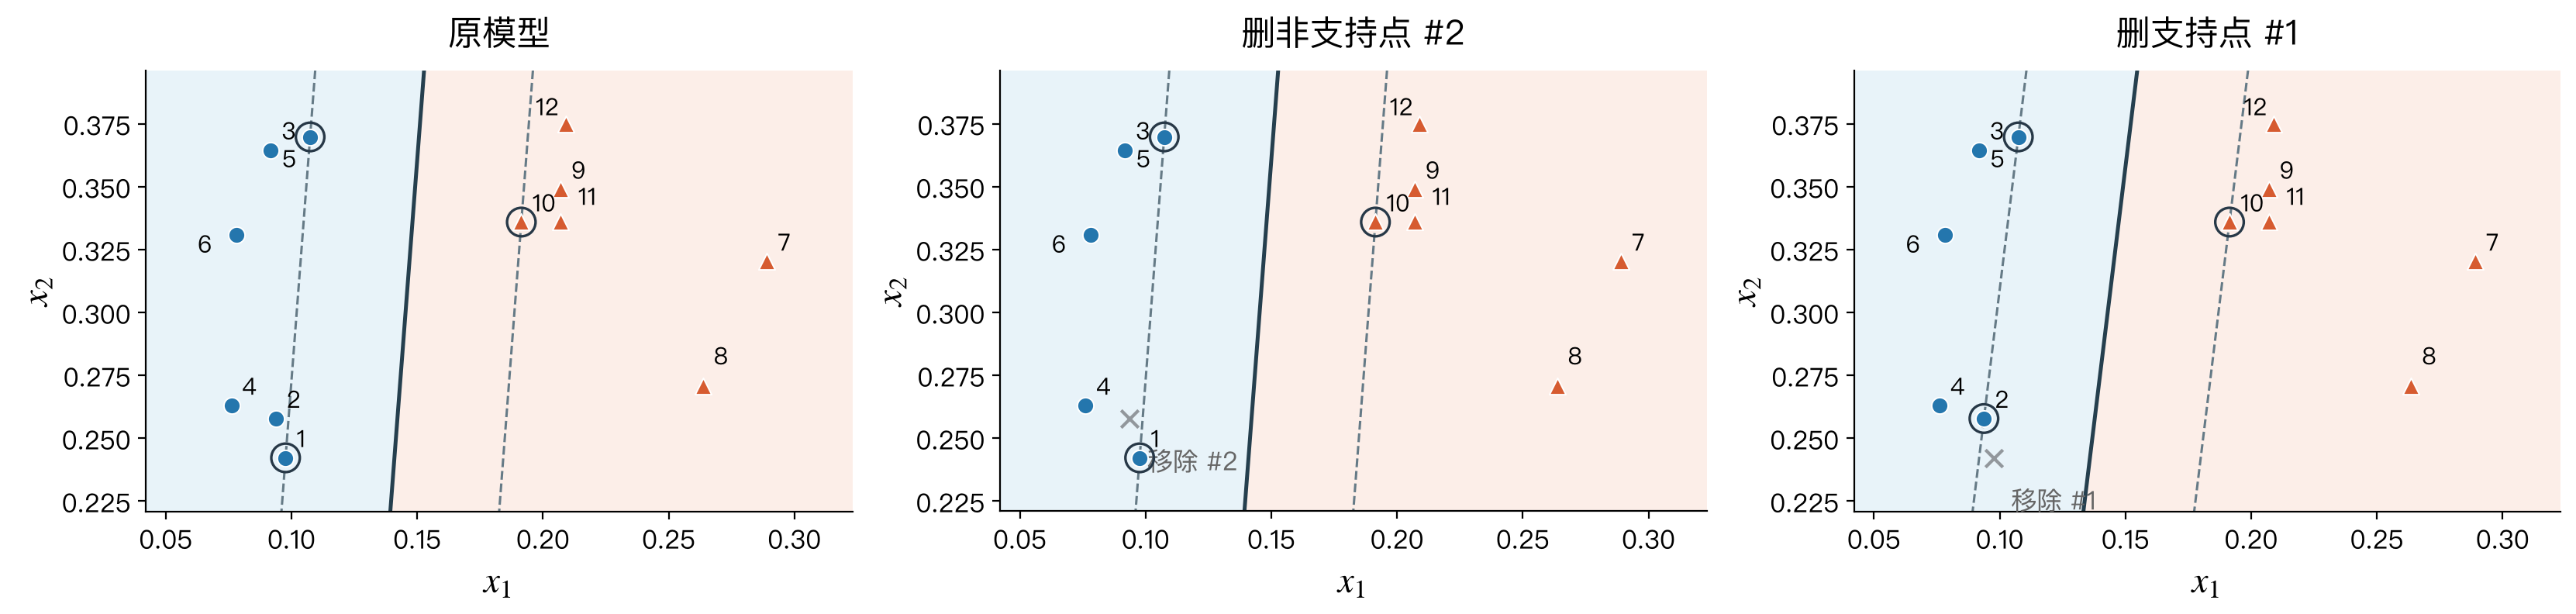

,kind,removed_point_id,w_delta_norm,b_delta
0,非支持向量,2,0.000000,0.000000
1,支持向量,1,1.081611,0.414405


In [11]:
results['support_removal'] = {'preprocessing':'none; fixed original coordinates',
    'C':10000, 'selection_rule':'first index in each category; no search for a moving example',
    'experiments':removal_rows,
    'caveat':'删除冗余支持向量不一定改变解；本例变化不推出所有数据的必然结论。'}
plot.panels('l8-support-removal', X, y, [linear]+removed_models,
    ['原模型', f'删非支持点 #{non_sv+1}', f'删支持点 #{sv+1}'],
    supports=[linear.support_]+remaining_supports, numbered=True, removed=[None,non_sv,sv])
display(pd.DataFrame(removal_rows)[['kind','removed_point_id','w_delta_norm','b_delta']])

## 3. 放回难分样本与软间隔（p9–p12）

在相同两轴放回全部 289 张 1 和 7。图中的重叠来自真实笔迹在两个摘要特征上的相似性。即使两张图看着不同，压缩后的两个数值也可能相同或接近。

<!-- # [ref:l8-noise] -->

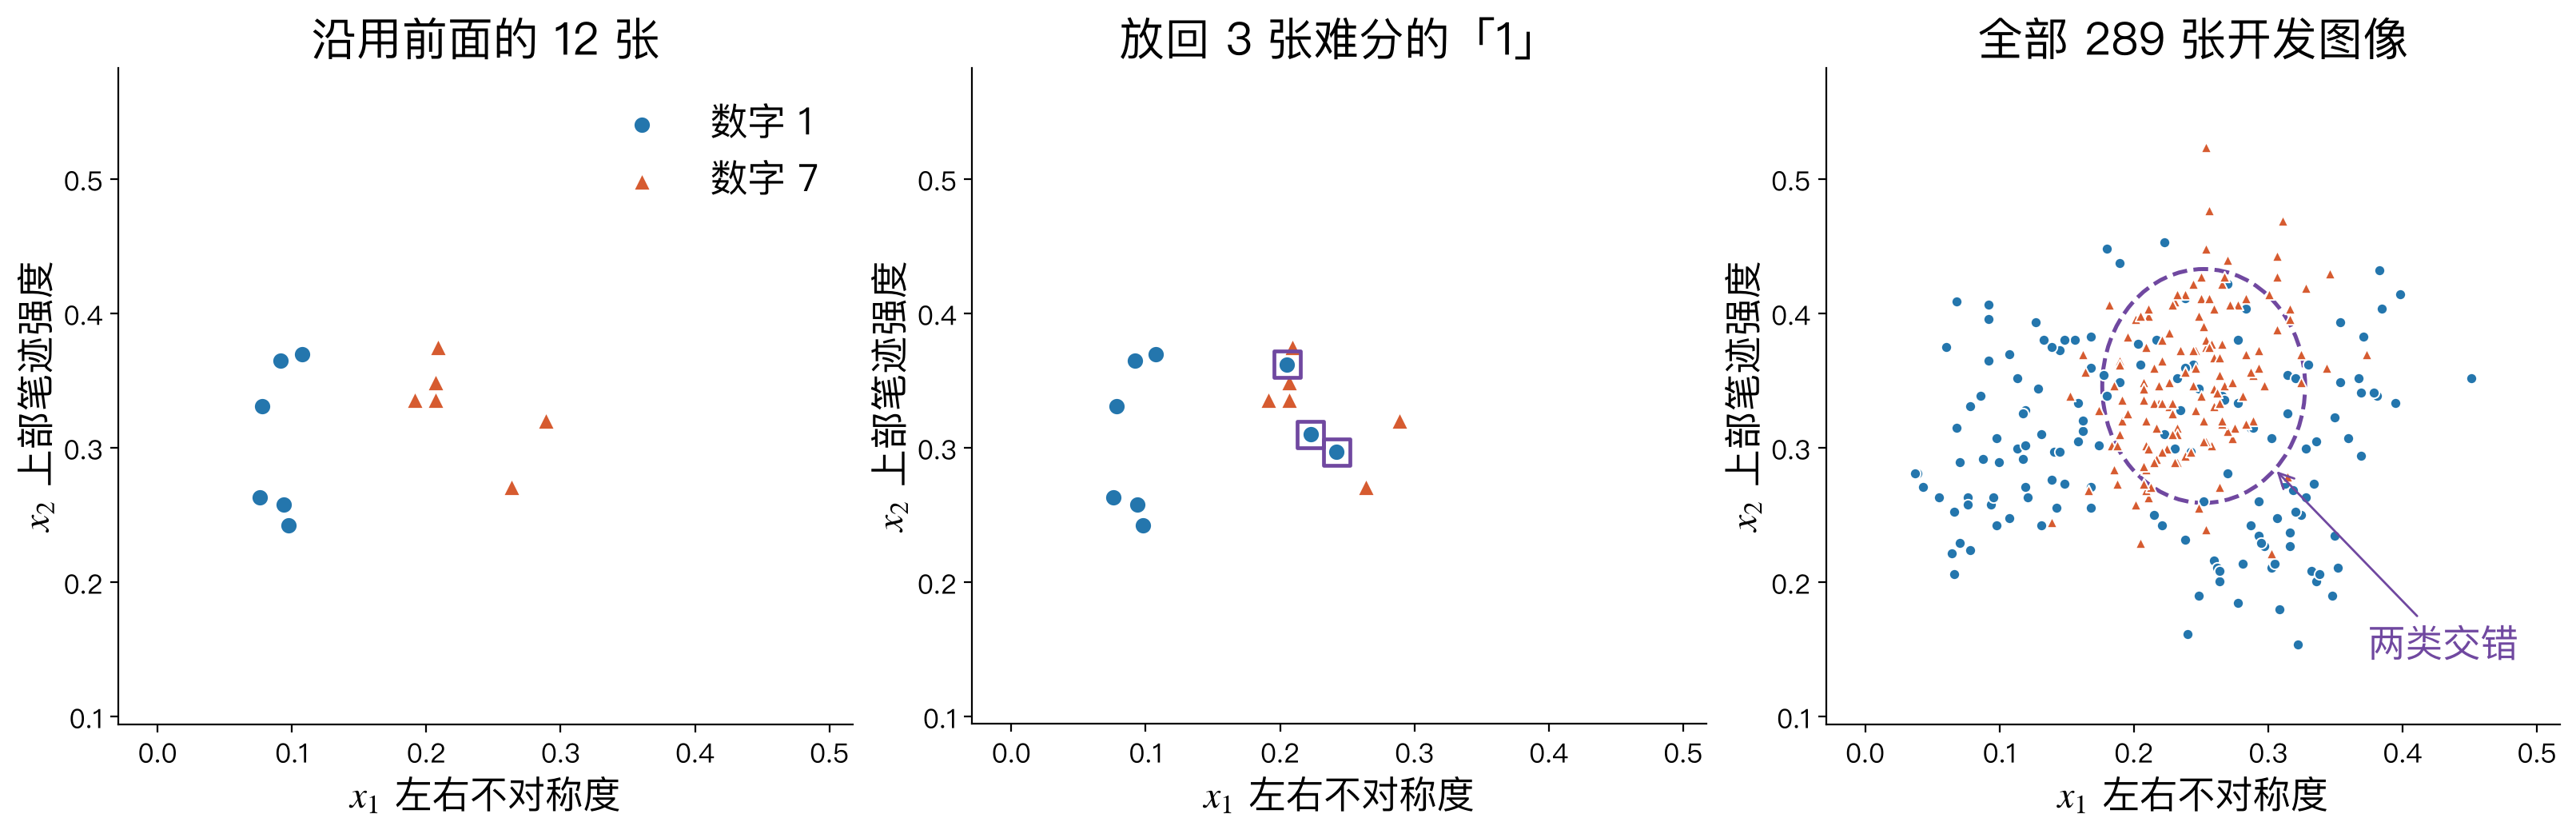

In [12]:
plot.digit_overlap(X, y, Xd, yd)

### 合页损失：分对但太近，也要罚

合页损失（hinge loss）为 $\ell_i=\max(0,1-s_i)$，$s_i=y_i f(x_i)$。先手算 A、B、C：$s=2.1,0.5,-0.3$。

这三个 $s$ 是用于手算的指定值，不冒充上述笔迹的实际分数。完整训练目标为 $\frac12\|w\|^2+C\sum_i\ell(y_if(x_i))$；单个样本的损失为 0，仍不能推出完整目标的梯度为 0。

<!-- # [ref:l8-hinge] -->

,样本,s,合页损失
0,A,2.1,0.0
1,B,0.5,0.5
2,C,-0.3,1.3


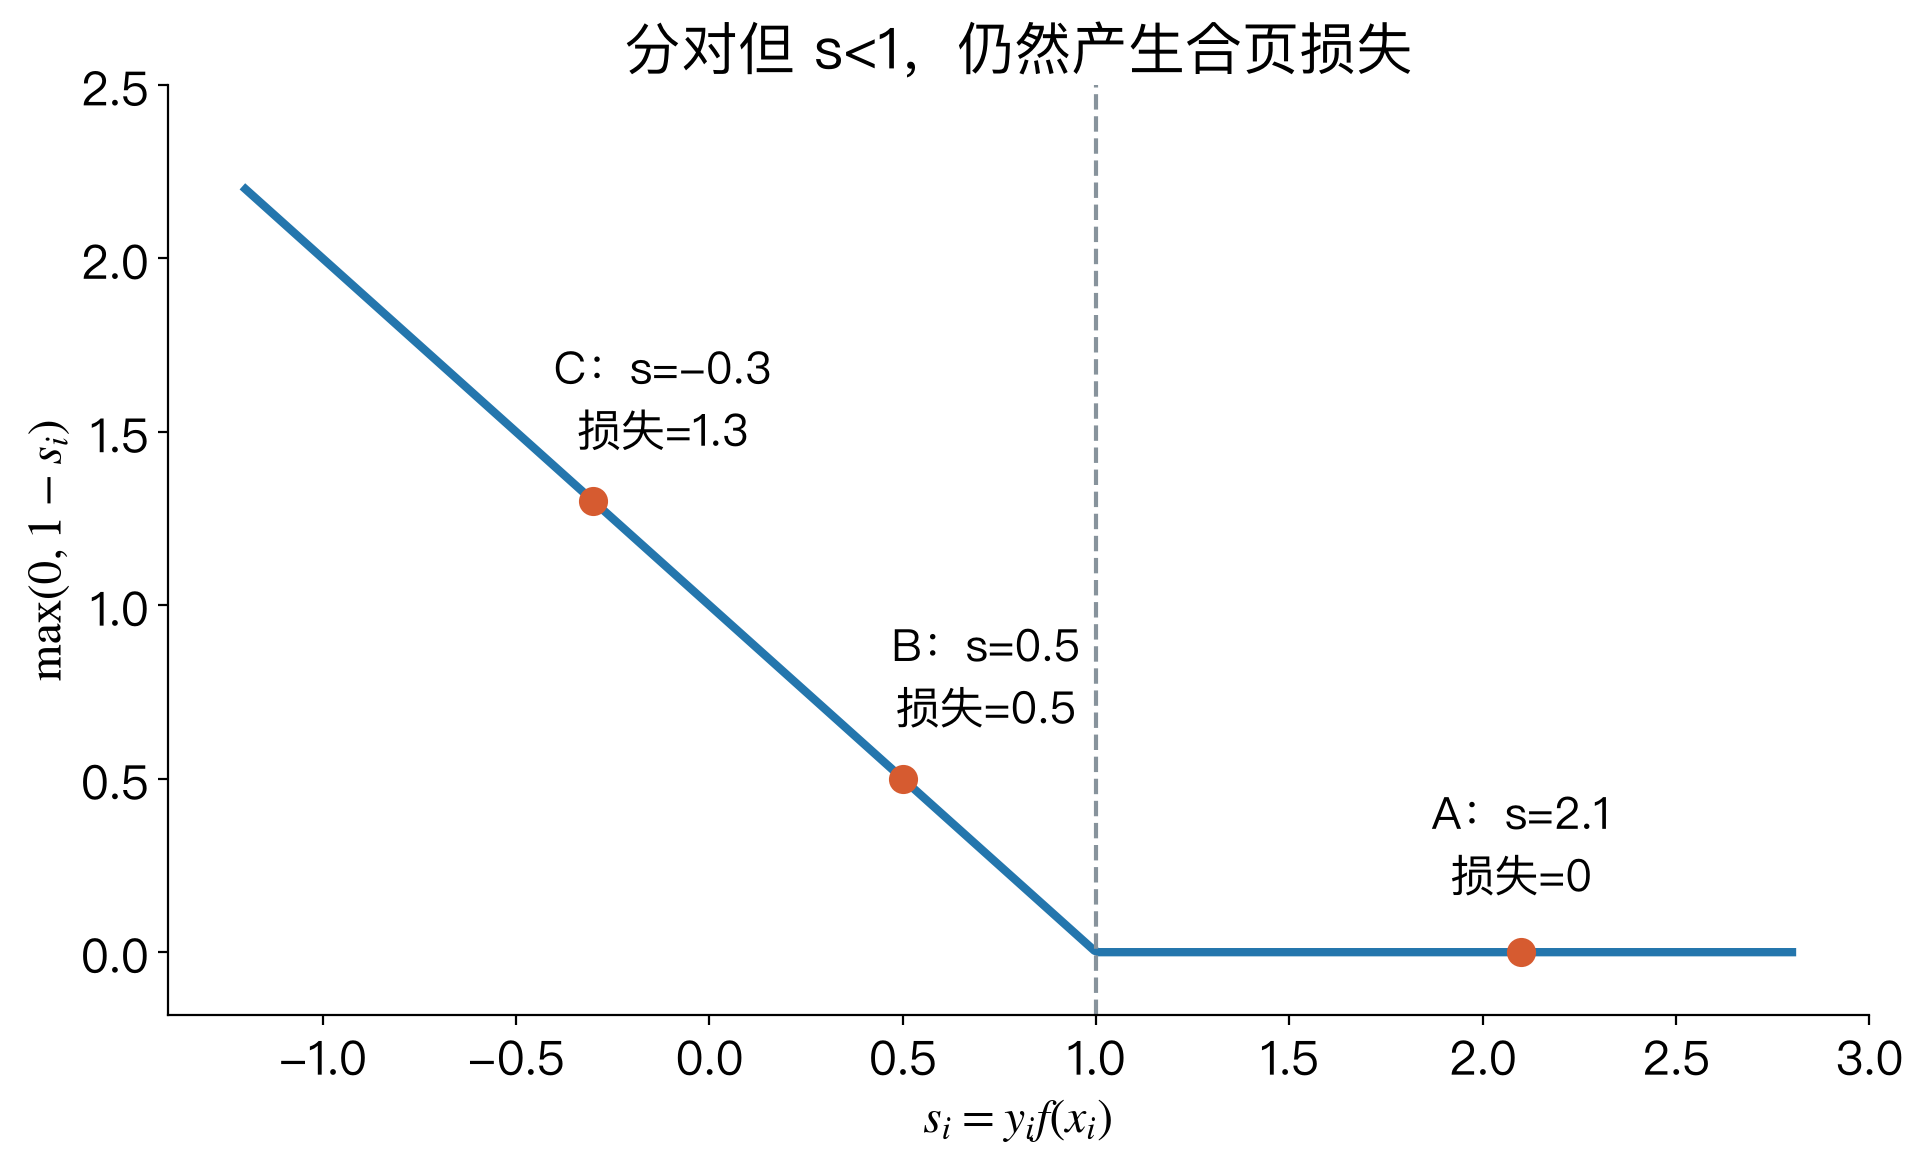

In [13]:
s = np.array([2.1, .5, -.3])
loss = np.maximum(0, 1-s)
results['hinge'] = {'point_ids':['A','B','C'], 's':s, 'loss':loss,
                    'interpretation':'specified signed-score examples, not measured noisy samples'}
display(pd.DataFrame({'样本':['A','B','C'], 's':s, '合页损失':loss}))
plot.hinge_plot(s, loss)

### 软间隔的总代价（p11）

用 p9 中间图的 15 个样本拟合线性 SVC。根据拟合后的分数计算每个点所需的最小松弛量，再分别算权重惩罚与样本惩罚。

总松弛量      7.484
权重惩罚     75.343
样本惩罚    748.416
总代价     823.759
dtype: float64

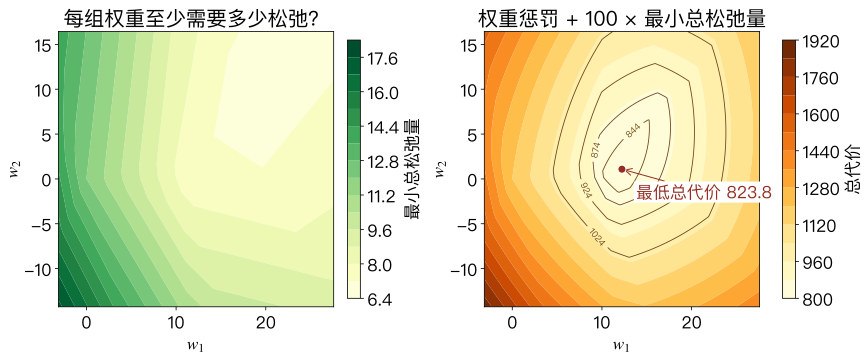

In [14]:
conflict_X, conflict_y = plot.digit_conflict_subset(X, y, Xd, yd)
soft_model = SVC(kernel='linear', C=100, tol=1e-9).fit(conflict_X, conflict_y)
signed_score = (2 * conflict_y - 1) * soft_model.decision_function(conflict_X)
slack = np.maximum(0, 1 - signed_score)
weight_cost = np.sum(soft_model.coef_**2) / 2
sample_cost = soft_model.C * slack.sum()
display(pd.Series({'总松弛量': slack.sum(), '权重惩罚': weight_cost,
                   '样本惩罚': sample_cost, '总代价': weight_cost + sample_cost}).round(3))
show_slide_figure('l8-soft-qp.svg')

### 固定数据，只改变 C

`C` 表示违反间隔的惩罚强度。比较相同开发数据上的 `C=0.01,0.1,10`，读训练错误数和支持向量数。这里不承诺边界形状或验证成绩随 `C` 严格单调。

**先判断**：如果两种数字的两个特征完全一样，增大 `C` 能把它们都分对吗？

<!-- # [ref:l8-c-sweep] -->

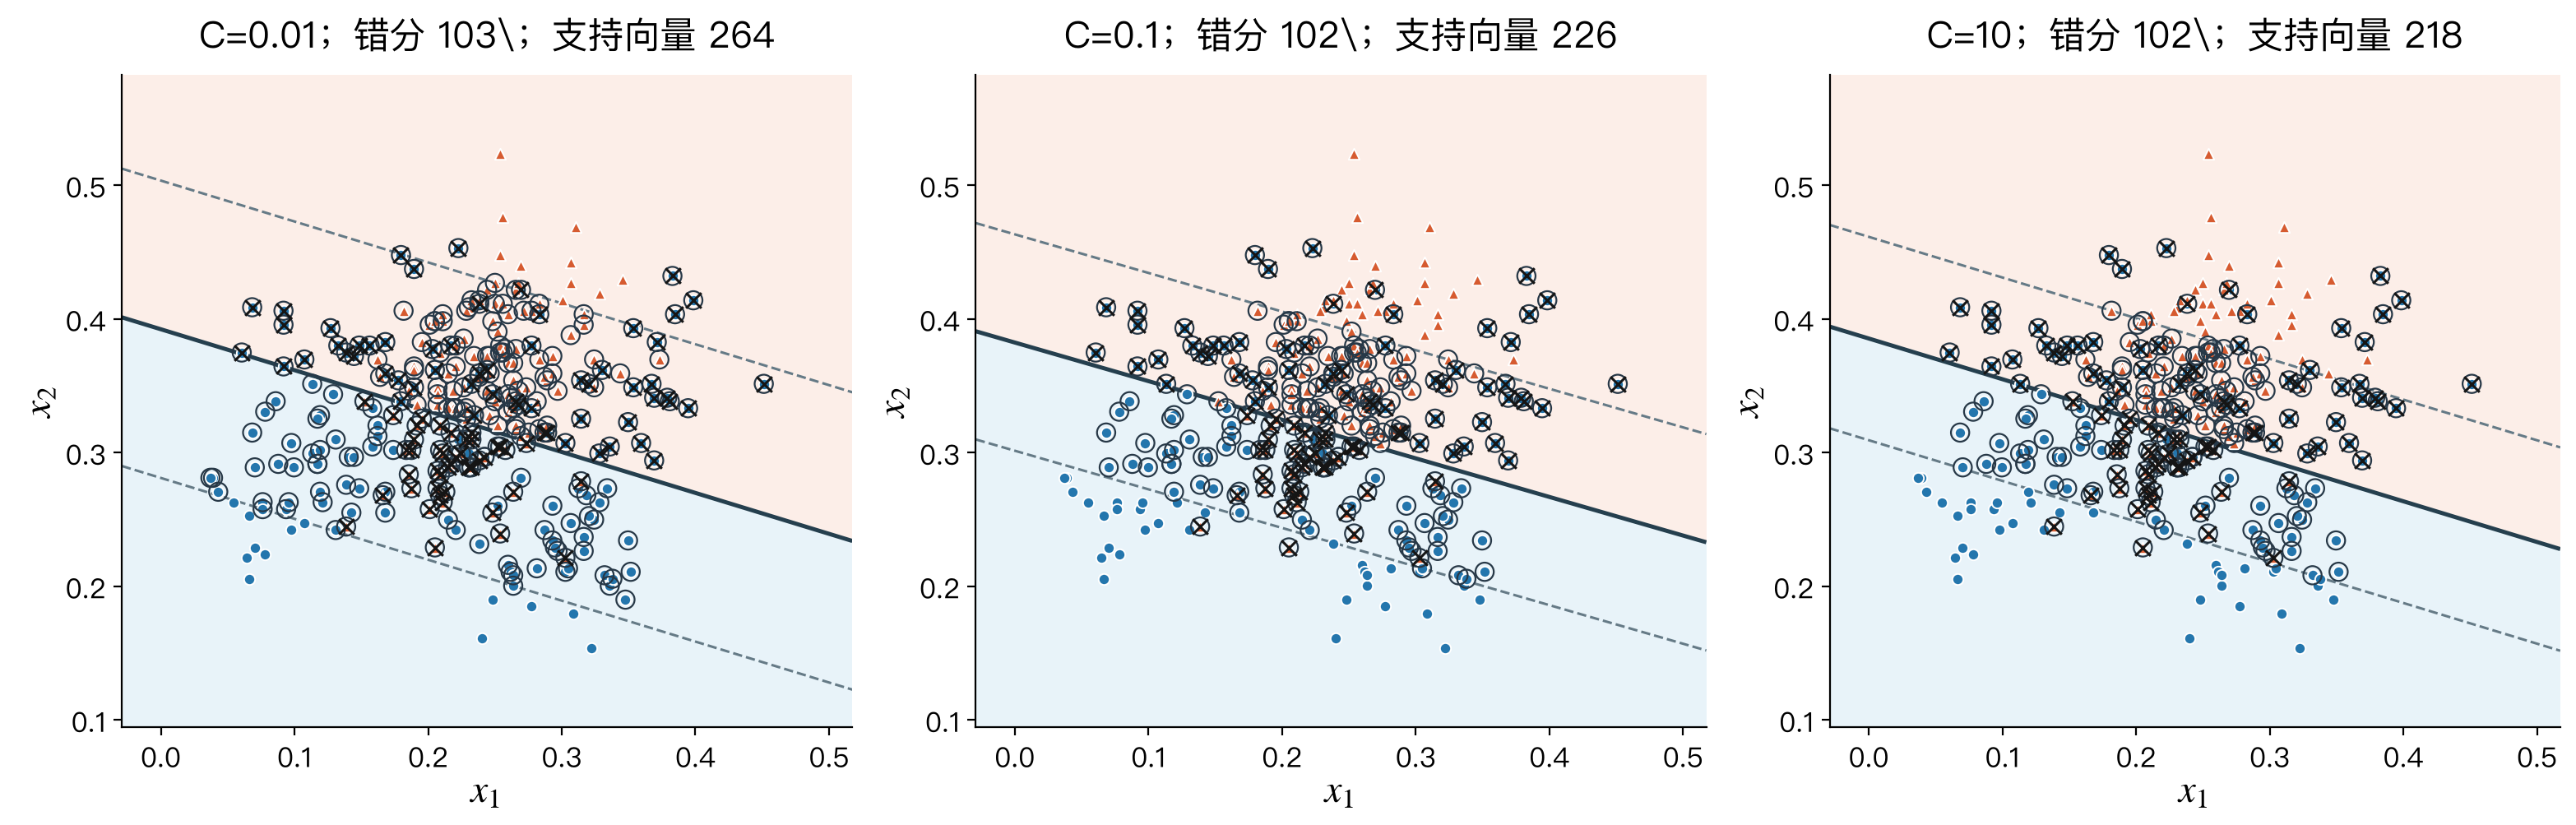

In [15]:
c_values = [.01, .1, 10]
c_models, c_rows = [], []
for C in c_values:
    model = make_pipeline(StandardScaler(), SVC(kernel='linear', C=C)).fit(Xd, yd)
    c_models.append(model)
    c_rows.append(plot.linear_record(model[-1], model[0].transform(Xd), yd))
results['c_sweep'] = c_rows
plot.panels('l8-c-sweep', Xd, yd, c_models,
    [f"C={r['C']:g}；错分 {r['errors']}\；支持向量 {sum(r['n_support'])}" for r in c_rows], supports=[m[-1].support_ for m in c_models])

## 4. 从 XOR 到核技巧（p13–p16）

四点 XOR 使用 $(0,0),(0,1),(1,0),(1,1)$，标签依次为 $0,1,1,0$。先复现 p13 的试分直线 $x_1+x_2=0.5$，再比较二次多项式特征＋逻辑回归与决策树。试分时，和大于 0.5 就预测为 1。下一小节单独加入交互项。

先用第7讲的决策树作对照。根节点按一个坐标切，两侧各有一正一负，基尼不纯度仍为0.5。允许再分一次，第二个坐标就能将两边分别分纯。

<!-- # [ref:l8-xor] -->

In [16]:
X_xor = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y_xor = np.array([0,1,1,0])
xor_tree = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_xor, y_xor)
line_prediction = (X_xor.sum(axis=1) > 0.5).astype(int)
poly_xor = make_pipeline(PolynomialFeatures(2, include_bias=False),
                         LogisticRegression(C=100, tol=1e-10, max_iter=2000)).fit(X_xor, y_xor)
print('试分直线的预测：', line_prediction)
print('错分的样本：', X_xor[line_prediction != y_xor])
print('二次多项式特征＋逻辑回归的预测：', poly_xor.predict(X_xor))
print('logit 权重与截距：', poly_xor[-1].coef_.round(3), poly_xor[-1].intercept_.round(3))
print(export_text(xor_tree, feature_names=['x1', 'x2']))
print('四点预测：', xor_tree.predict(X_xor))
print('根节点与两个子节点的Gini：', xor_tree.tree_.impurity[[0, xor_tree.tree_.children_left[0],
    xor_tree.tree_.children_right[0]]])

试分直线的预测： [0 1 1 1]
错分的样本： [[1. 1.]]
二次多项式特征＋逻辑回归的预测： [0 1 1 0]
logit 权重与截距： [[ 2.033  2.033  2.033 -8.566  2.033]] [-1.934]
|--- x1 <= 0.50
|   |--- x2 <= 0.50
|   |   |--- class: 0
|   |--- x2 >  0.50
|   |   |--- class: 1
|--- x1 >  0.50
|   |--- x2 <= 0.50
|   |   |--- class: 1
|   |--- x2 >  0.50
|   |   |--- class: 0

四点预测： [0 1 1 0]
根节点与两个子节点的Gini： [0.5 0.5 0.5]


### 用交互项改变SVM的输入

对应 p14，第三维直接设为 $x_1x_2$。只有 $(1,1)$ 被抬到高度 1。下面在三个特征上拟合线性 SVM。

In [17]:
X_interaction = np.c_[X_xor, X_xor[:, 0] * X_xor[:, 1]]
interaction_svm = SVC(kernel='linear', C=100, tol=1e-8).fit(X_interaction, y_xor)
print('权重与截距：', interaction_svm.coef_.round(3), interaction_svm.intercept_.round(3))
print('四点分数：', interaction_svm.decision_function(X_interaction).round(3))

权重与截距： [[ 2.  2. -4.]] [-1.]
四点分数： [-1.  1.  1. -1.]


### 映射后点积，能否直接算？

为了得到标准二次多项式核，改用显式映射 $\phi(x)=(x_1^2,\sqrt2x_1x_2,x_2^2)$，核对 $\phi(a)^T\phi(b)=(a^Tb)^2$。对 $a=(1,2)$、$b=(2,3)$，三项贡献为 $4+24+36=64$。

`PolynomialFeatures` 未加权输出不自动满足这个等式；中间项的 $\sqrt2$ 不能漏。

<!-- # [ref:l8-kernel] -->

In [18]:
def phi_quad(data):
    data = np.asarray(data)
    x1, x2 = data[..., 0], data[..., 1]
    return np.stack([x1**2, np.sqrt(2) * x1 * x2, x2**2], axis=-1)

a, b_pair = np.array([1.,2.]), np.array([2.,3.])
explicit_dot = np.dot(phi_quad(a), phi_quad(b_pair))
kernel_dot = (a @ b_pair)**2
assert np.allclose(explicit_dot, kernel_dot)
quad_linear = SVC(kernel='linear', C=100, tol=1e-8).fit(phi_quad(X_xor), y_xor)
quad_kernel = SVC(kernel='poly', degree=2, gamma=1, coef0=0, C=100, tol=1e-8).fit(X_xor,y_xor)
check_points = np.random.default_rng(42).normal(size=(100,2))
max_score_delta = np.max(np.abs(quad_linear.decision_function(phi_quad(check_points))-
                                quad_kernel.decision_function(check_points)))

In [19]:
results['kernel_equivalence'] = {'a':a, 'b':b_pair, 'phi_a':phi_quad(a), 'phi_b':phi_quad(b_pair),
    'explicit_dot':explicit_dot, 'kernel_dot':kernel_dot, 'max_score_delta':max_score_delta,
    'kernel_params':{'kernel':'poly','degree':2,'gamma':1,'coef0':0,'C':100},
    'check_points':check_points, 'same_C':True}
assert max_score_delta < 1e-6, '同一核与显式映射的分数应在数值容差内一致'
print('映射后点积：', explicit_dot, '直接算核：', kernel_dot, '最大分数差：', max_score_delta)

映射后点积： 64.0 直接算核： 64.0 最大分数差： 7.105427357601002e-15


### 三种核会画出怎样的决策边界？

对应 p16。固定数据、标准化和 C，比较线性核、二次多项式核与高斯核。

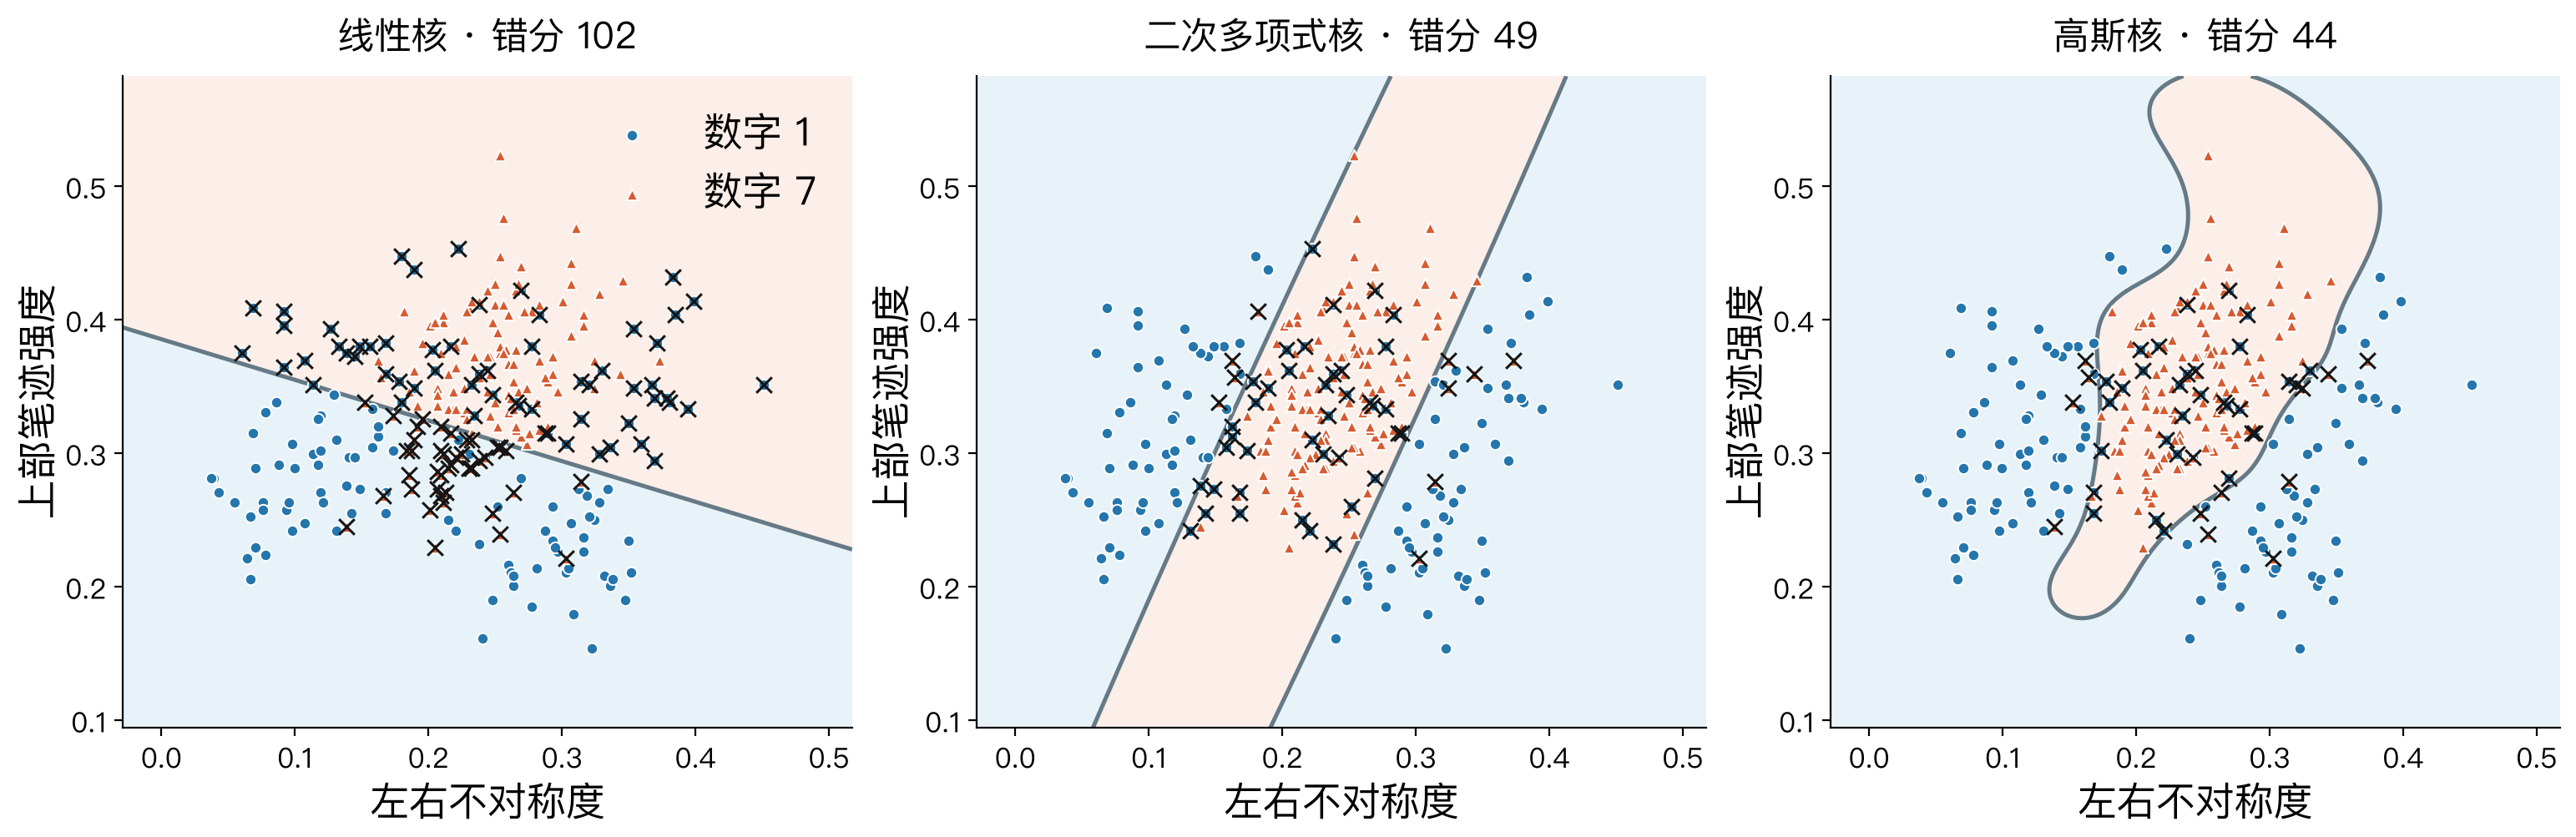

In [20]:
kernel_names = ['线性核', '二次多项式核', '高斯核']
kernel_settings = [
    {'kernel': 'linear'}, {'kernel': 'poly', 'degree': 2, 'gamma': 1, 'coef0': 0},
    {'kernel': 'rbf', 'gamma': 1},
]
kernel_models = [make_pipeline(StandardScaler(), SVC(C=10, **params)).fit(Xd, yd)
                 for params in kernel_settings]
headings = [f'{name} · 错分 {np.count_nonzero(model.predict(Xd) != yd)}'
            for name, model in zip(kernel_names, kernel_models)]
plot.panels('l8-notebook-three-kernels', Xd, yd, kernel_models, headings, show_levels=False)

## 5. 高斯核：相似度随距离怎样变化？

scikit-learn 的高斯核（`kernel="rbf"`）为 $K(x,z)=\exp(-\gamma\|x-z\|^2)$。固定距离 $d=1$，比较 `gamma=0.1,1,10`。

`gamma` 控制相似度衰减范围；它不表示要取多少个邻居，也不是一条线的斜率。

<!-- # [ref:l8-rbf] -->

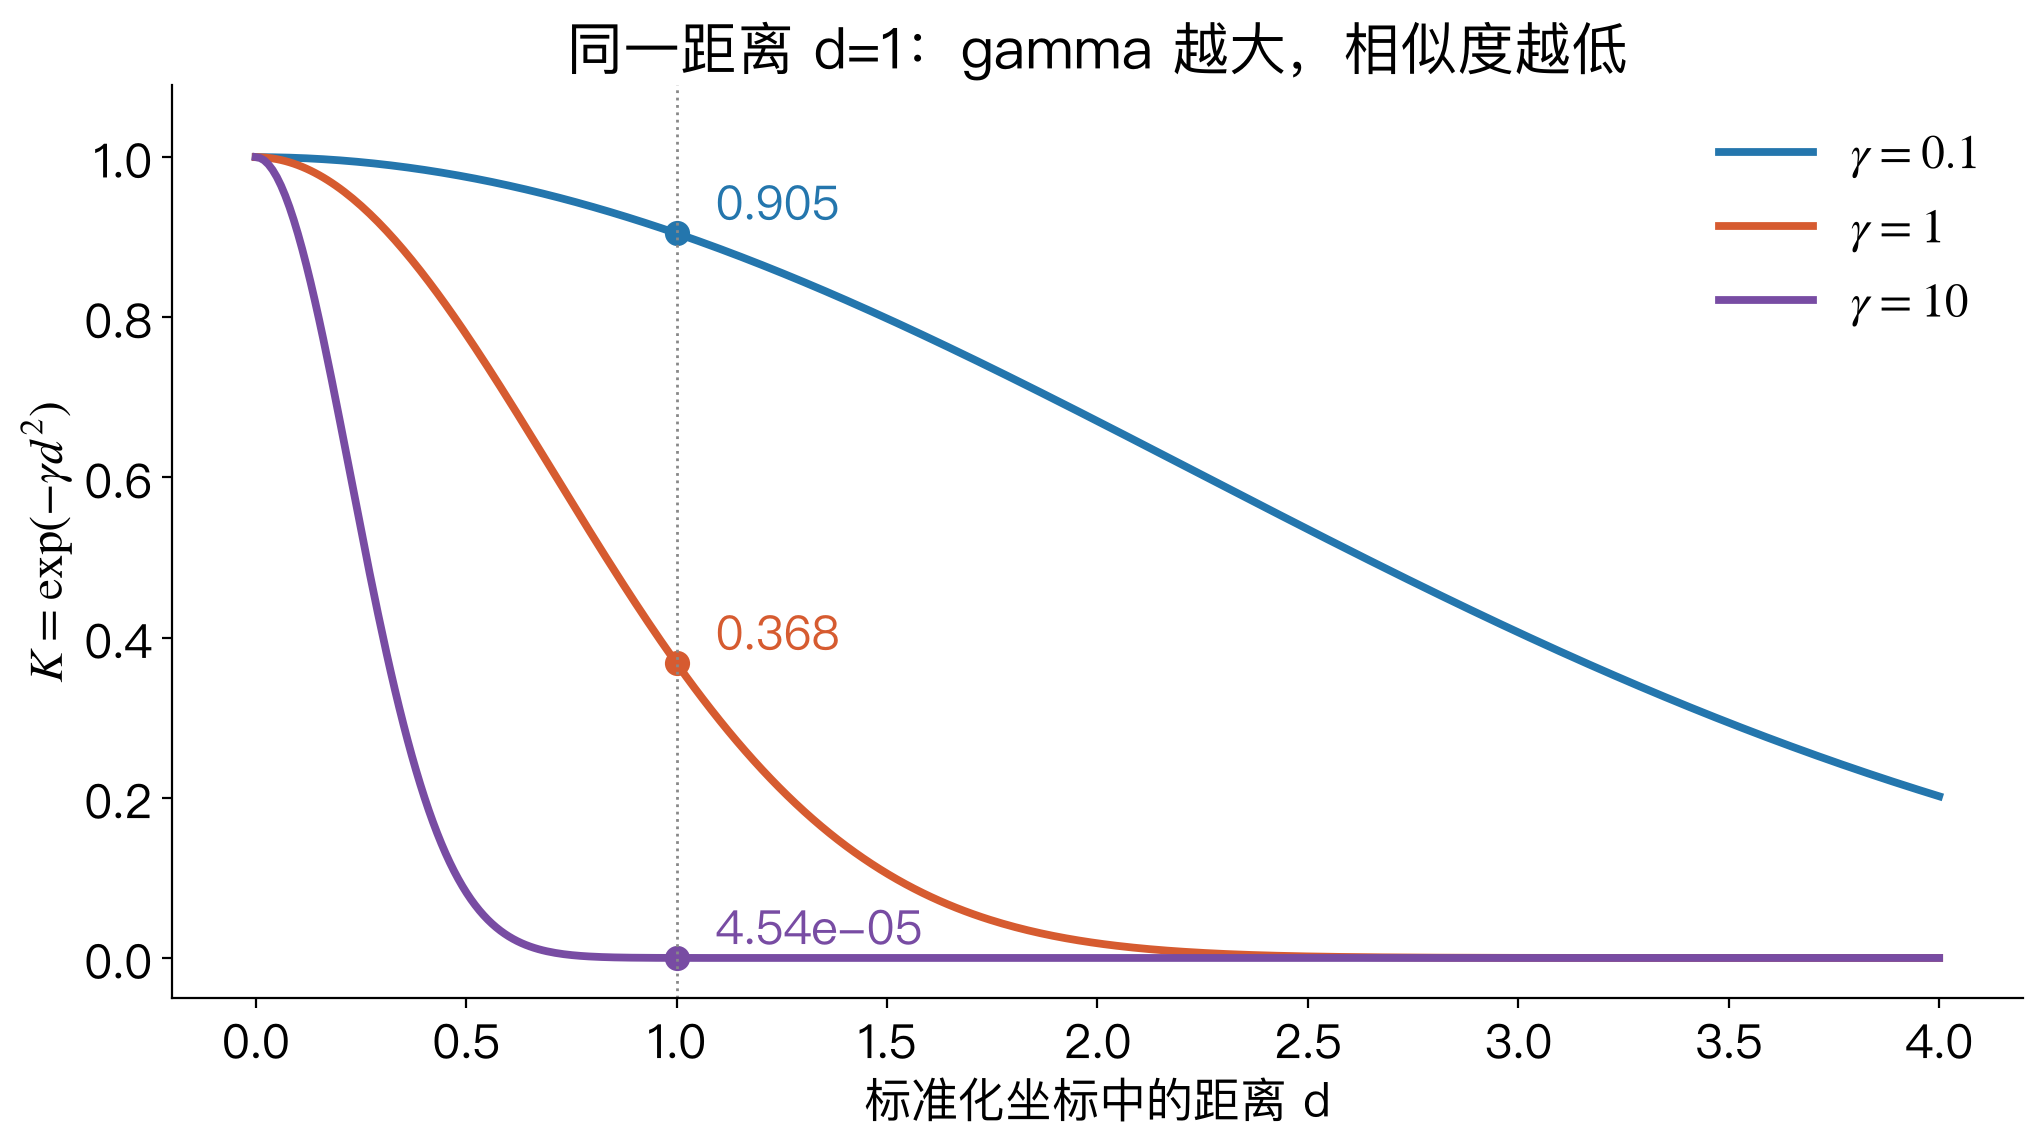

In [21]:
rbf_gammas = [.1, 1, 10]
results['rbf_similarity'] = {'gamma_values':rbf_gammas, 'distance':1,
                            'similarity_at_distance_1':np.exp(-np.asarray(rbf_gammas))}
plot.rbf_plot(rbf_gammas)

### 在 1 和 7 上固定 C，改变 gamma

同一批 289 张开发图像和相同的分层五折。每折先拟合标准化，再拟合 SVM。边界在全部开发样本上重训后绘制，选参看验证均值。

<!-- # [ref:l8-gamma] -->

,gamma,验证均值,支持向量数
0,0.01,0.500000,287
1,1.00,0.838005,201
2,10.00,0.693448,288


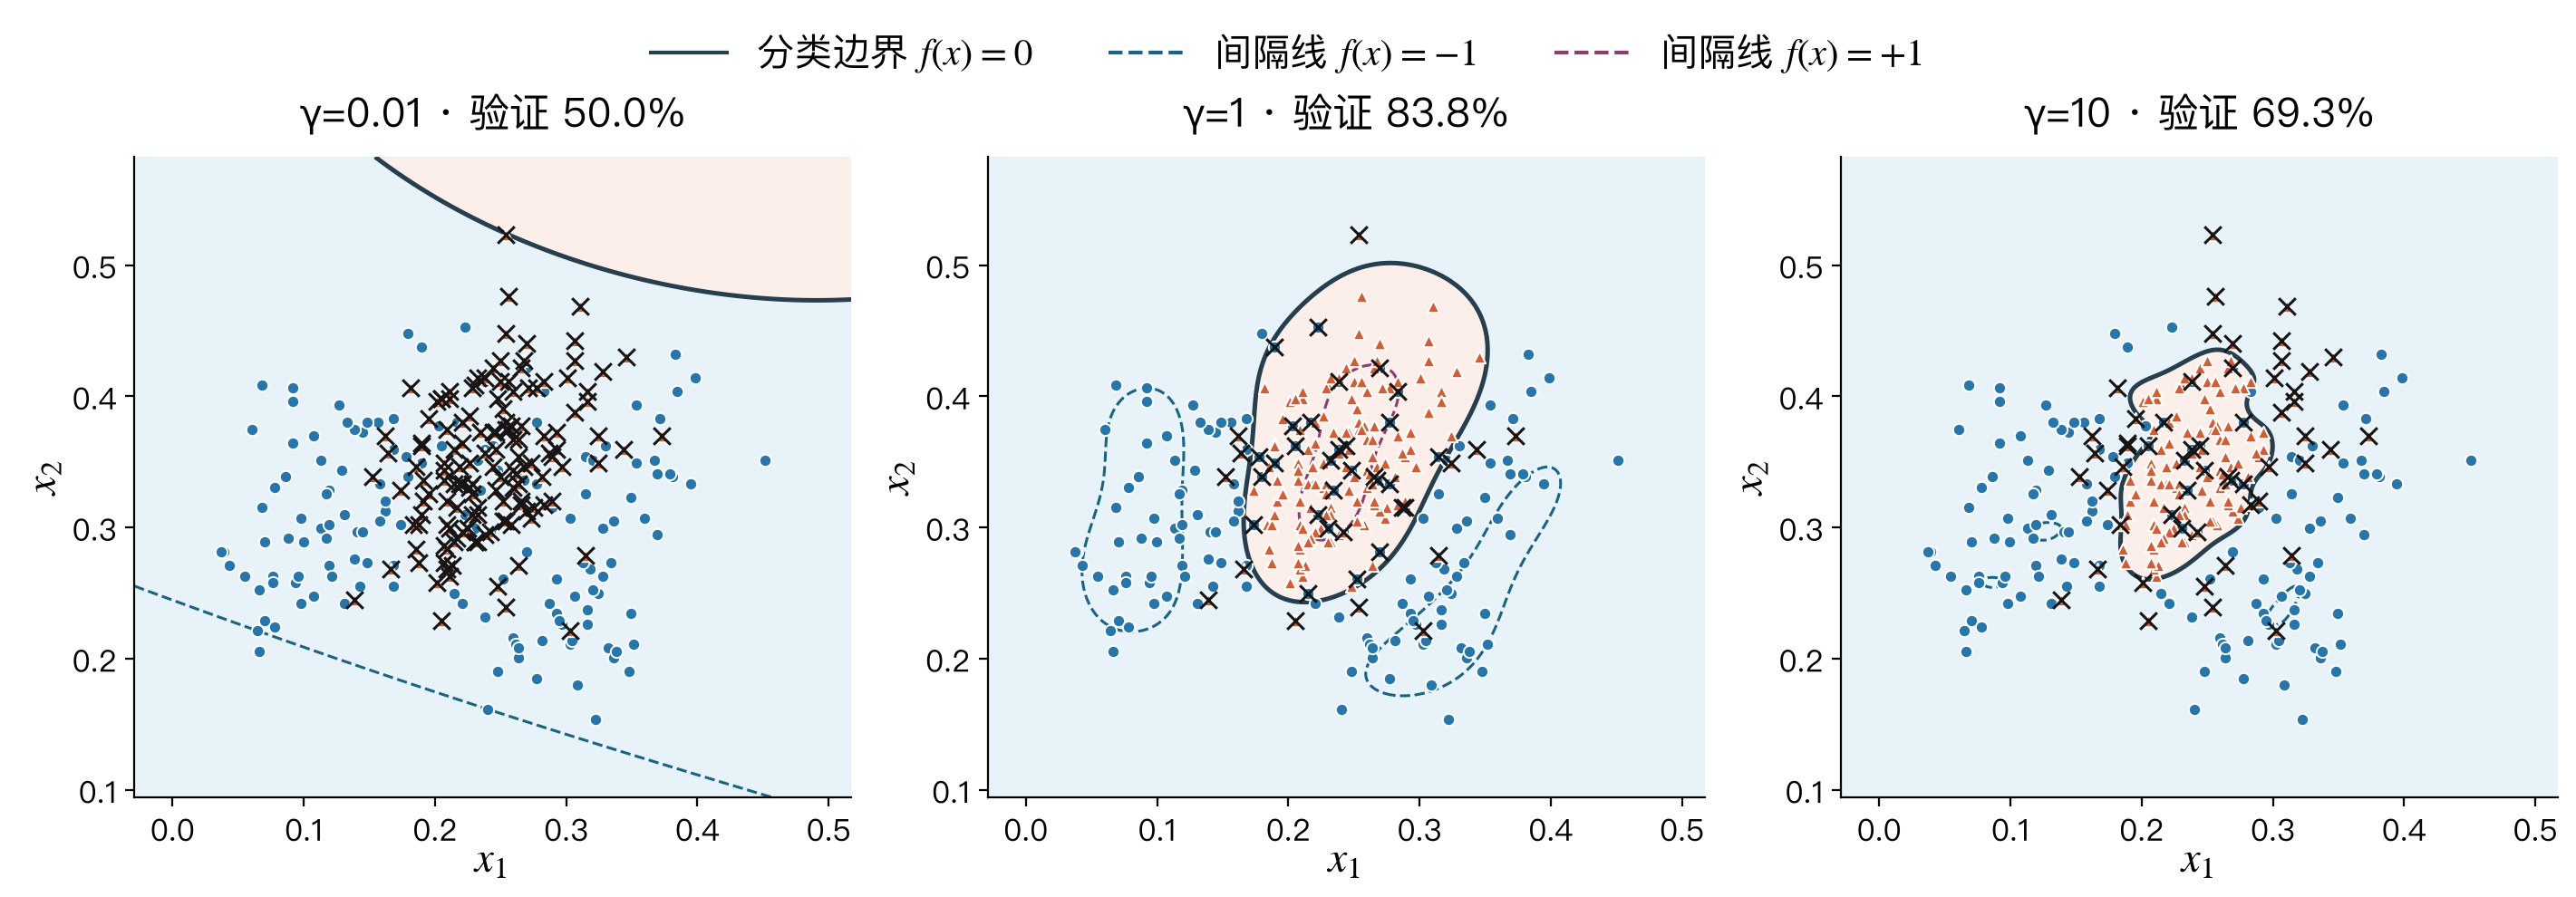

In [22]:
folds = StratifiedKFold(5, shuffle=True, random_state=42)
rbf_pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
gamma_models, gamma_rows = [], []
for gamma in [.01, 1, 10]:
    model = clone(rbf_pipe).set_params(svc__C=.1, svc__gamma=gamma).fit(Xd, yd)
    scores = cross_val_score(model, Xd, yd, cv=folds, scoring='balanced_accuracy')
    gamma_models.append(model)
    gamma_rows.append((gamma, scores.mean(), len(model[-1].support_)))
display(pd.DataFrame(gamma_rows, columns=['gamma', '验证均值', '支持向量数']))
plot.panels('l8-gamma-sweep', Xd, yd, gamma_models,
    [f'γ={g:g} · 验证 {score:.1%}' for g, score, _ in gamma_rows])

### 横向改 gamma，纵向改 C

在同一批样本上比较两个参数怎样共同改变边界。图中的实线是决策分数为 0 的位置。虚线是分数为 ±1 的等值线。

<!-- # [ref:l8-c-gamma] -->

,C,γ,训练准确率,五折平均平衡准确率
0,0.1,0.01,0.5052,0.5000
1,0.1,1.00,0.8512,0.8380
2,0.1,10.00,0.8097,0.6934
3,1.0,0.01,0.6678,0.6545
4,1.0,1.00,0.8478,0.8279
5,1.0,10.00,0.8685,0.8134
6,10.0,0.01,0.7543,0.7489
7,10.0,1.00,0.8478,0.8278
8,10.0,10.00,0.9135,0.7513


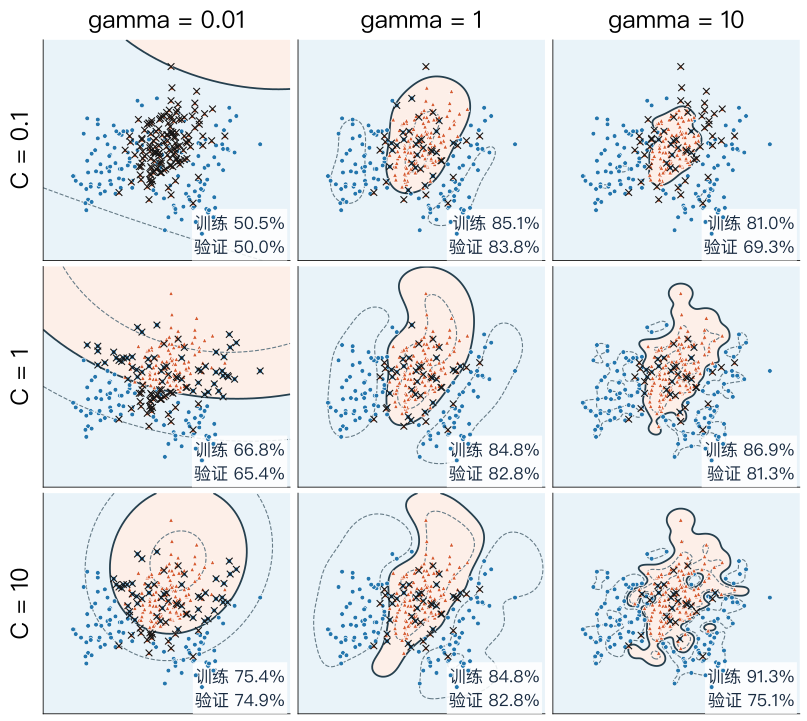

In [23]:
grid_rows = []
for C in [.1, 1, 10]:
    for gamma in [.01, 1, 10]:
        model = clone(rbf_pipe).set_params(svc__C=C, svc__gamma=gamma).fit(Xd, yd)
        validation = cross_val_score(model, Xd, yd, cv=folds, scoring='balanced_accuracy').mean()
        grid_rows.append((C, gamma, model.score(Xd, yd), validation))
display(pd.DataFrame(grid_rows, columns=['C', 'γ', '训练准确率', '五折平均平衡准确率']).round(4))
show_slide_figure('l8-c-gamma-grid.svg')

### 用五折验证比较 C 和 γ

每格是相同五折的平衡准确率均值。用相同 C 候选比较线性核和 RBF，RBF 还需要选择 gamma。

<!-- # [ref:l8-search] -->

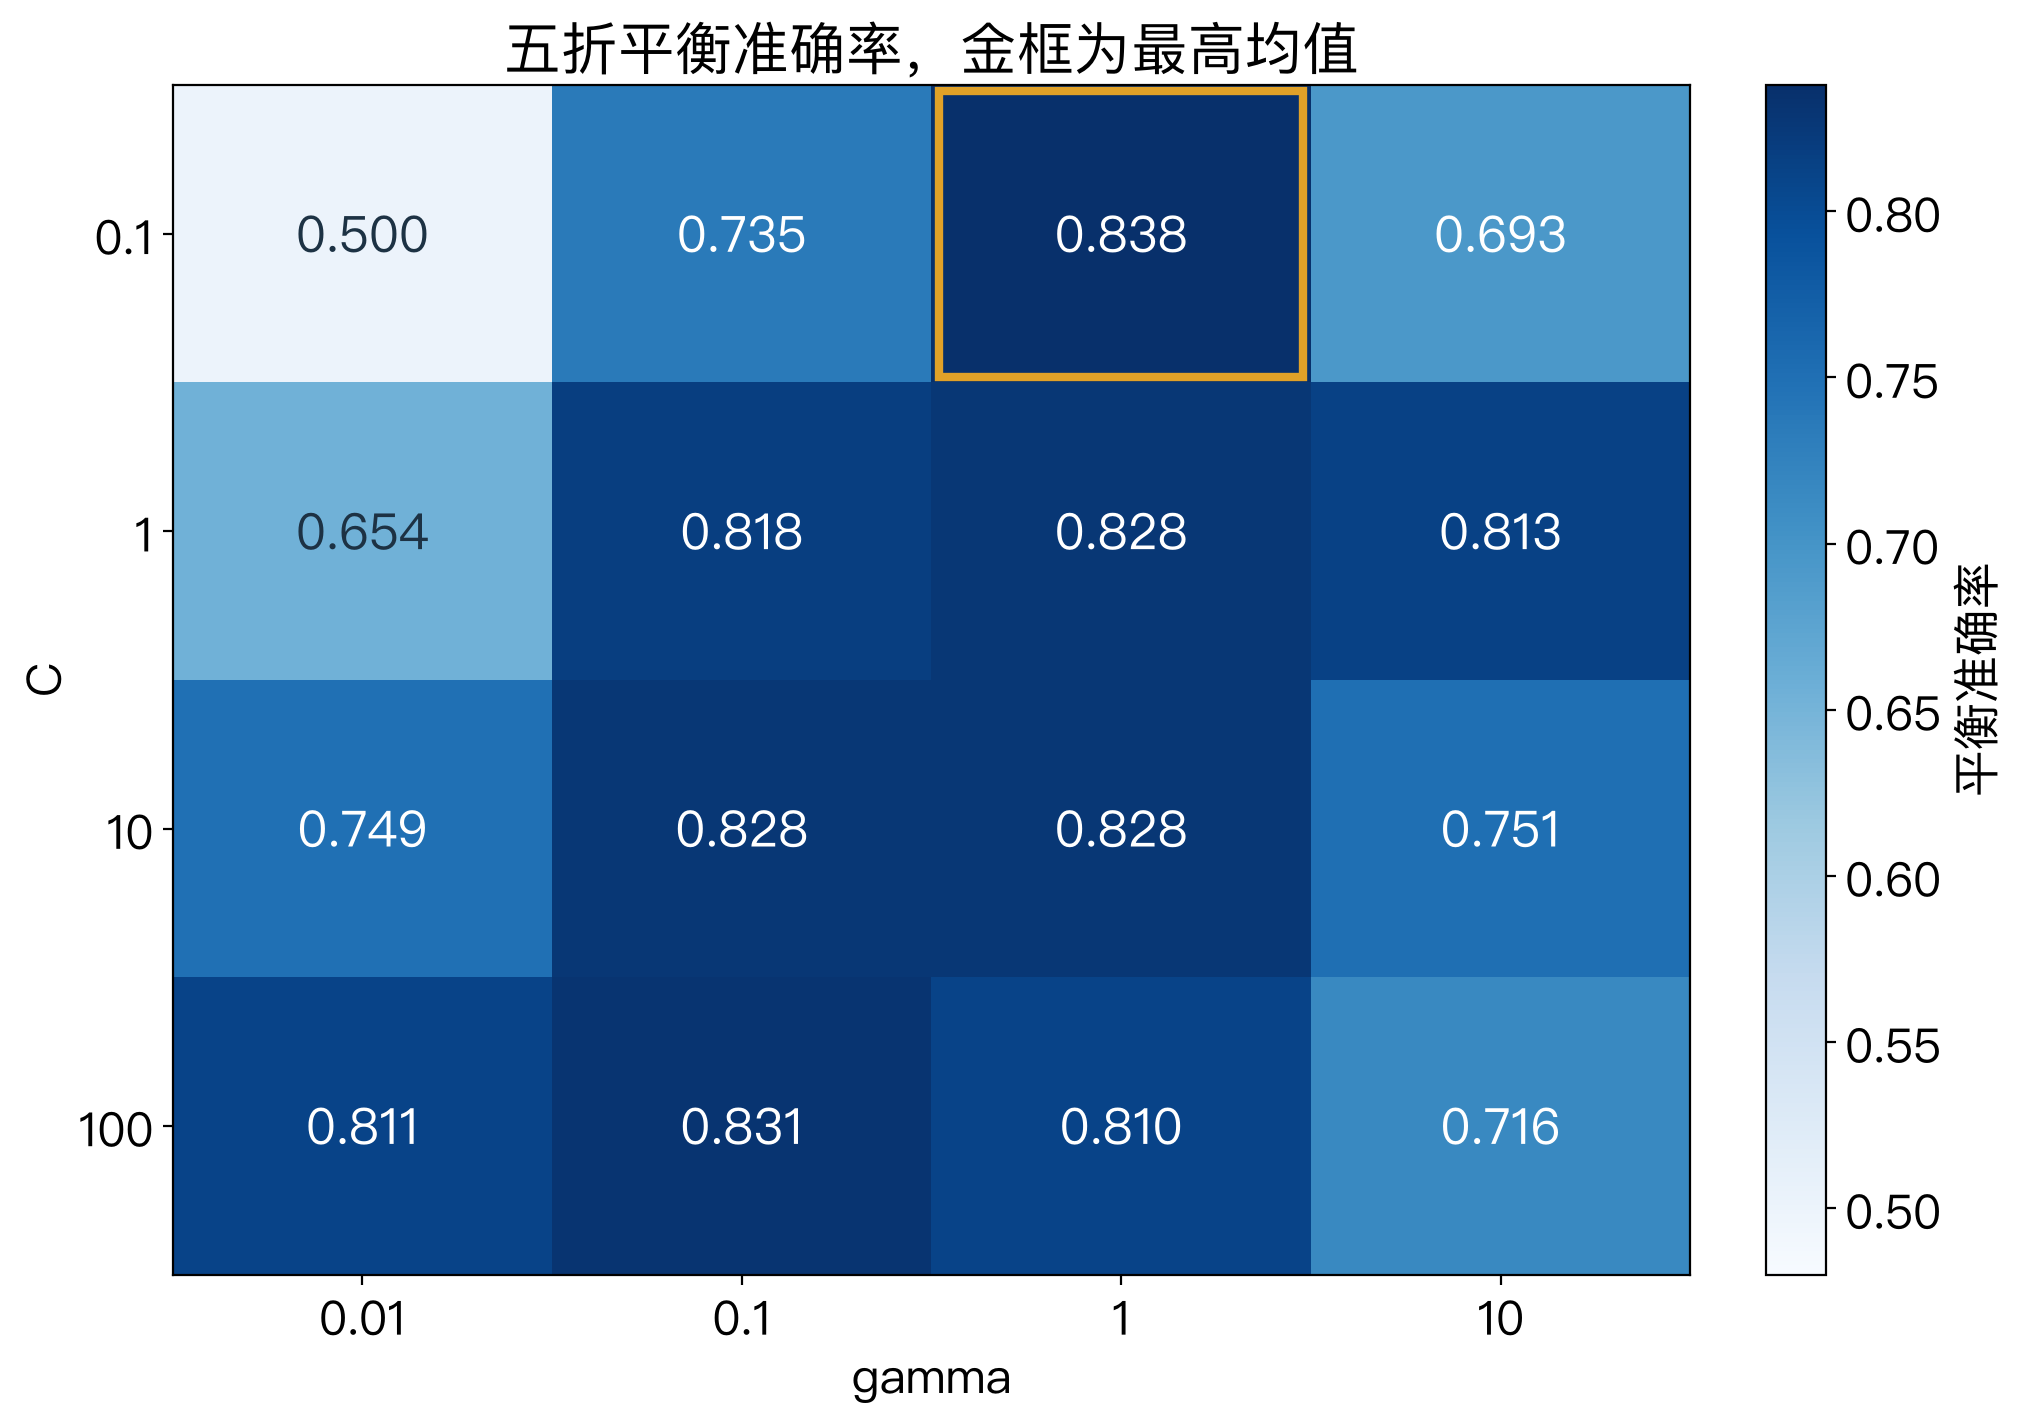

0.6405582922824301 {'svc__C': 0.1} 0.8380049261083744 {'svc__C': 0.1, 'svc__gamma': 1}


In [24]:
C_values, gamma_values = [.1, 1, 10, 100], [.01, .1, 1, 10]
def search_kernel(X, y, kernel, grid):
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel))
    return GridSearchCV(model, grid, cv=folds, scoring='balanced_accuracy').fit(X, y)

linear_2d = search_kernel(Xd, yd, 'linear', {'svc__C': C_values})
rbf_2d = search_kernel(Xd, yd, 'rbf', {'svc__C': C_values, 'svc__gamma': gamma_values})
plot.heatmap(C_values, gamma_values, rbf_2d.cv_results_['mean_test_score'], rbf_2d.best_index_)
print(linear_2d.best_score_, linear_2d.best_params_, rbf_2d.best_score_, rbf_2d.best_params_)

In [25]:
cv_results = rbf_2d.cv_results_
fold_table = pd.DataFrame({
    'C': cv_results['param_svc__C'], 'gamma': cv_results['param_svc__gamma'],
    **{f'第{i+1}折': cv_results[f'split{i}_test_score'] for i in range(5)},
    '均值': cv_results['mean_test_score'],
})
display(fold_table.round(4))

,C,gamma,第1折,第2折,第3折,第4折,第5折,均值
0,0.1,0.01,0.5000,0.5000,0.5000,0.5000,0.5000,0.5000
1,0.1,0.10,0.7798,0.7241,0.7586,0.6897,0.7223,0.7349
2,0.1,1.00,0.8286,0.8103,0.8448,0.8276,0.8787,0.8380
3,0.1,10.00,0.6286,0.6724,0.7586,0.6552,0.7525,0.6934
4,1.0,0.01,0.7071,0.6897,0.6207,0.6034,0.6515,0.6545
5,1.0,0.10,0.8476,0.7759,0.8448,0.7759,0.8442,0.8177
6,1.0,1.00,0.8298,0.7759,0.8621,0.8276,0.8442,0.8279
7,1.0,10.00,0.7571,0.8103,0.8276,0.8103,0.8615,0.8134
8,10.0,0.01,0.7976,0.7241,0.7931,0.6897,0.7401,0.7489
9,10.0,0.10,0.8298,0.7759,0.8448,0.8103,0.8787,0.8279


### 新样本的分数从哪里来？

二分类核 SVM 使用 $f(x)=\sum_{i\in SV}\alpha_i y_iK(x_i,x)+b$。`dual_coef_` 已经包含标签的符号；下面逐项核对真实训练模型的输出。

每个支持向量贡献一个带符号的分数，最后加上截距。

<!-- # [ref:l8-kernel-predict] -->

In [26]:
query = np.array([.4, -.7])
k_values = (quad_kernel.support_vectors_ @ query)**2
contributions = quad_kernel.dual_coef_[0] * k_values
manual_score = contributions.sum() + quad_kernel.intercept_[0]
api_score = quad_kernel.decision_function(query.reshape(1,-1))[0]
assert np.allclose(manual_score, api_score)
results['kernel_predict'] = {'query':query, 'support_indices':quad_kernel.support_,
    'signed_dual_coefficients':quad_kernel.dual_coef_[0], 'kernel_values':k_values,
    'contributions':contributions, 'intercept':quad_kernel.intercept_[0],
    'manual_score':manual_score, 'api_score':api_score}
display(pd.DataFrame({'支持点索引':quad_kernel.support_, '核值':k_values,
    '带符号权重':quad_kernel.dual_coef_[0], '分数贡献':contributions}).round(3))
print('加截距后：', manual_score, 'API：', api_score)

,支持点索引,核值,带符号权重,分数贡献
0,0,0.00,-6.0,-0.00
1,3,0.09,-2.0,-0.18
2,1,0.49,4.0,1.96
3,2,0.16,4.0,0.64


加截距后： 1.4199999961386474 API： 1.4199999961386474


### 决策分数怎样变成标签？

下面查看最靠近零分边界的六张开发图像。正分对应 7，负分对应 1。

<!-- # [ref:l8-scores] -->

In [27]:
score = rbf_2d.decision_function(Xd)
near = np.argsort(np.abs(score), kind='stable')[:6]
display(pd.DataFrame({'原始索引': digit_ids[near], '分数': score[near],
    '实际数字': digits.target[digit_ids[near]], '预测数字': rbf_2d.predict(Xd[near]) * 6 + 1}).round(3))

,原始索引,分数,实际数字,预测数字
0,235,-0.024,1,1
1,85,-0.037,1,1
2,1243,0.056,7,7
3,693,0.061,1,7
4,93,-0.095,1,1
5,1556,-0.098,1,1


## 6. 比较五种模型的决策边界（p21）

沿用两项摘要特征。五种模型在同样的分层五折划分上选参。这里报告平衡准确率，并用相同的 72 张预留图像算测试分数。课件图还标出了测量时的 CPU 开销。

<!-- # [ref:l8-five-summary] -->

In [28]:
def classifier_candidates(pixels=False, multiclass=False):
    penalties = [.01, .1, 1, 10, 100] if pixels else C_values
    gammas = ['scale', .001, .003, .01, .03, .1] if pixels else gamma_values
    logistic = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False),
                             LogisticRegression(max_iter=2000))
    return [
        ('高斯核 SVM', rbf_pipe,
         {'svc__C': [.1, 1, 10] if multiclass else penalties,
          'svc__gamma': [.003, .01, .03] if multiclass else gammas}),
        ('多项式特征＋Logistic 回归', logistic,
         {'polynomialfeatures__degree': [2] if pixels else [2, 3],
          'logisticregression__C': [.01, .1, 1] if multiclass else penalties}),
        ('kNN', make_pipeline(StandardScaler(), KNeighborsClassifier()),
         {'kneighborsclassifier__n_neighbors': [3, 5, 9, 15] if multiclass else [3, 5, 9, 15, 25]}),
        ('决策树', DecisionTreeClassifier(random_state=42),
         {'max_depth': [5, 10, None] if multiclass else [2, 3, 5],
          'min_samples_leaf': [1, 3] if multiclass else [3, 8, 15]}),
        ('梯度提升树', GradientBoostingClassifier(random_state=42),
         {'max_depth': [1, 2] if multiclass else [1, 2, 3],
          'n_estimators': [60, 100] if multiclass else [30, 60, 100]}),
    ]

,模型,最佳参数,五折均值（平衡准确率）,训练,测试
0,高斯核 SVM,"{'svc__C': 0.1, 'svc__gamma': 1}",0.8380,0.8518,0.8056
1,多项式特征＋Logistic 回归,"{'logisticregression__C': 10, 'polynomialfeatu...",0.8449,0.8554,0.8194
2,kNN,{'kneighborsclassifier__n_neighbors': 25},0.8281,0.8418,0.8194
3,决策树,"{'max_depth': 5, 'min_samples_leaf': 3}",0.8134,0.8757,0.7500
4,梯度提升树,"{'max_depth': 2, 'n_estimators': 60}",0.8242,0.8759,0.8056


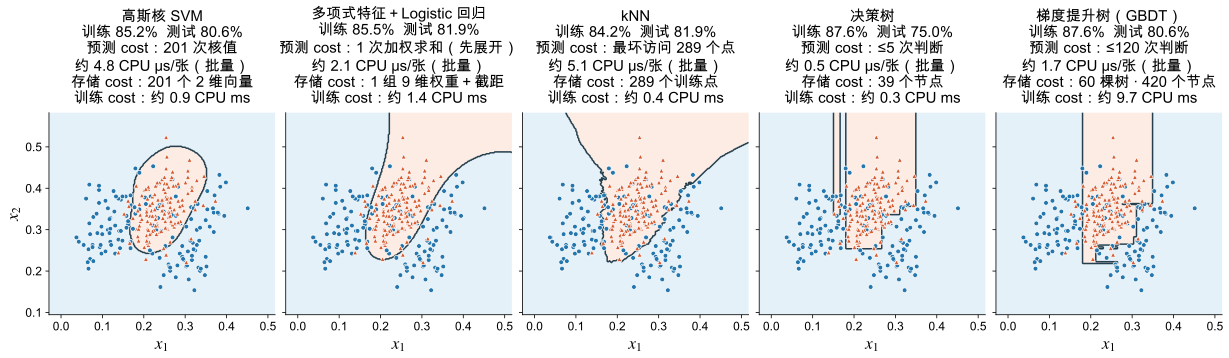

In [29]:
def fit_and_compare(candidates, X_train, y_train, X_test, y_test, metric):
    rows = []
    for name, estimator, params in candidates:
        search = GridSearchCV(estimator, params, cv=folds, scoring='balanced_accuracy',
                              error_score='raise').fit(X_train, y_train)
        model = search.best_estimator_
        rows.append({'模型': name, '最佳参数': search.best_params_, '五折均值（平衡准确率）': search.best_score_,
                     '训练': metric(y_train, model.predict(X_train)),
                     '测试': metric(y_test, model.predict(X_test))})
    return pd.DataFrame(rows)

summary_table = fit_and_compare(
    classifier_candidates(), Xd, yd, features[binary_test_ids], y_test, balanced_accuracy_score)
display(summary_table.round(4))
show_slide_figure('l8-five-classifiers.svg')

## 7. 用 8×8 像素做特征（p22）

仍然识别手写 1 和 7。先比较两项摘要特征与完整像素上的线性核、高斯核。每种特征表示下独立选参。课件右侧用 UMAP 二维逆映射展示原模型的决策区域，下面的分数直接用原模型输入计算。

<!-- # [ref:l8-real-cv] -->

,模型,最佳参数,五折均值（平衡准确率）,训练,测试
0,两项摘要 · 线性核,{'svc__C': 0.1},0.6406,0.6477,0.5972
1,两项摘要 · 高斯核,"{'svc__C': 0.1, 'svc__gamma': 1}",0.8380,0.8518,0.8056
2,64 像素 · 线性核,{'svc__C': 0.01},1.0000,1.0000,1.0000
3,64 像素 · 高斯核,"{'svc__C': 0.1, 'svc__gamma': 0.003}",1.0000,1.0000,1.0000


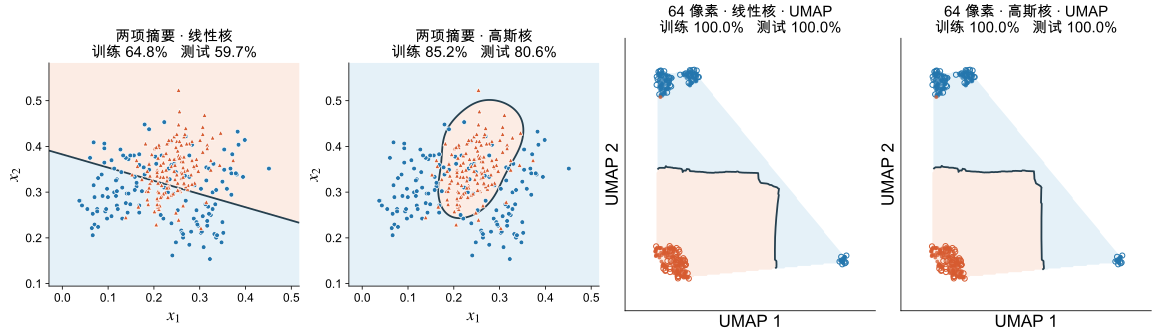

In [30]:
X_pixels = digits.data[digit_ids]
X_pixels_test = digits.data[binary_test_ids]
linear_grid = {'svc__C': [.01, .1, 1, 10, 100]}
rbf_grid = {**linear_grid, 'svc__gamma': ['scale', .001, .003, .01, .03, .1]}
pixel_svm_table = fit_and_compare([
    ('64 像素 · 线性核', make_pipeline(StandardScaler(), SVC(kernel='linear')), linear_grid),
    ('64 像素 · 高斯核', rbf_pipe, rbf_grid),
], X_pixels, yd, X_pixels_test, y_test, balanced_accuracy_score)
summary_svm_table = pd.DataFrame([
    {'模型': f'两项摘要 · {name}', '最佳参数': search.best_params_,
     '五折均值（平衡准确率）': search.best_score_, '训练': search.score(Xd, yd),
     '测试': search.score(features[binary_test_ids], y_test)}
    for name, search in [('线性核', linear_2d), ('高斯核', rbf_2d)]
])
display(pd.concat([summary_svm_table, pixel_svm_table], ignore_index=True).round(4))
show_slide_figure('l8-pixel-boundaries.svg')

## 8. 8×8 像素，比较五种模型（p23）

五种模型都改用 64 个像素，再各自在开发集内选参。对照 p21 的测试分数，观察更换特征后发生了什么。

<!-- # [ref:l8-five-pixels] -->

,模型,最佳参数,五折均值（平衡准确率）,训练,测试
0,高斯核 SVM,"{'svc__C': 0.1, 'svc__gamma': 0.003}",1.0000,1.0000,1.0000
1,多项式特征＋Logistic 回归,"{'logisticregression__C': 0.01, 'polynomialfea...",1.0000,1.0000,1.0000
2,kNN,{'kneighborsclassifier__n_neighbors': 15},1.0000,1.0000,1.0000
3,决策树,"{'max_depth': 2, 'min_samples_leaf': 3}",0.9828,0.9966,0.9722
4,梯度提升树,"{'max_depth': 1, 'n_estimators': 60}",0.9930,1.0000,1.0000


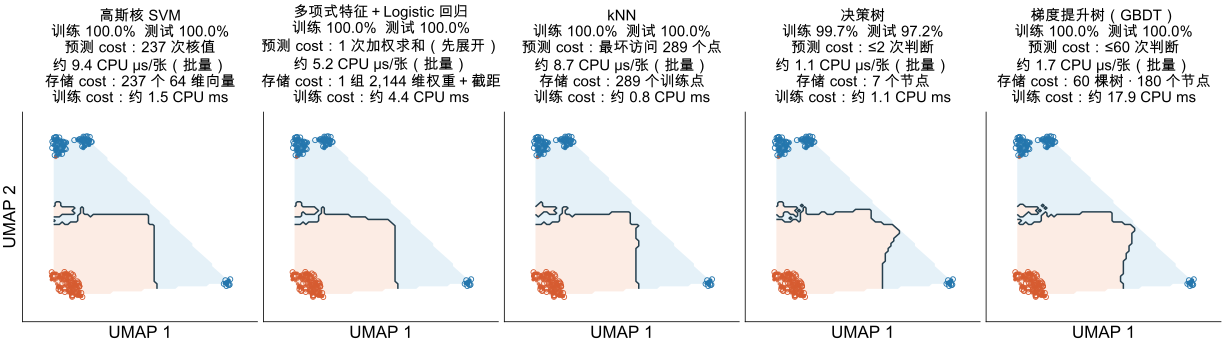

In [31]:
pixel_table = fit_and_compare(
    classifier_candidates(pixels=True), X_pixels, yd, X_pixels_test, y_test, balanced_accuracy_score)
display(pixel_table.round(4))
show_slide_figure('l8-five-classifiers-pixels.svg')

## 9. 用 8×8 像素识别全部十类数字（p24）

选参仍用平衡准确率，训练、测试表改报普通准确率。两个实验使用同一总体划分，十分类测试集包含前面的 72 张 1 和 7。

<!-- # [ref:l8-all-digits] -->

In [32]:
all_digits_table = fit_and_compare(
    classifier_candidates(pixels=True, multiclass=True),
    digits.data[dev_ids], digits.target[dev_ids], digits.data[test_ids], digits.target[test_ids],
    accuracy_score)
display(all_digits_table.round(4))

,模型,最佳参数,五折均值（平衡准确率）,训练,测试
0,高斯核 SVM,"{'svc__C': 10, 'svc__gamma': 0.03}",0.9812,1.0000,0.9778
1,多项式特征＋Logistic 回归,"{'logisticregression__C': 0.1, 'polynomialfeat...",0.9818,1.0000,0.9861
2,kNN,{'kneighborsclassifier__n_neighbors': 3},0.9764,0.9882,0.9667
3,决策树,"{'max_depth': None, 'min_samples_leaf': 1}",0.8446,1.0000,0.8222
4,梯度提升树,"{'max_depth': 2, 'n_estimators': 100}",0.9650,1.0000,0.9500


## 扩展阅读 A｜更多核函数（p25）

从左到右是高斯、拉普拉斯、指数卡方、余弦和 Sigmoid 核。先比较固定参考点的核值，再观察训练边界。指数卡方核需要非负输入，因此使用最小最大缩放并裁剪。其余使用标准化。各模型取 C=1，适用时取 γ=1，Sigmoid 的常数项取 0。

<!-- # [ref:l8-more-kernels] -->

,核函数,训练错分
0,高斯,44
1,拉普拉斯,39
2,指数卡方,64
3,余弦,99
4,Sigmoid,138


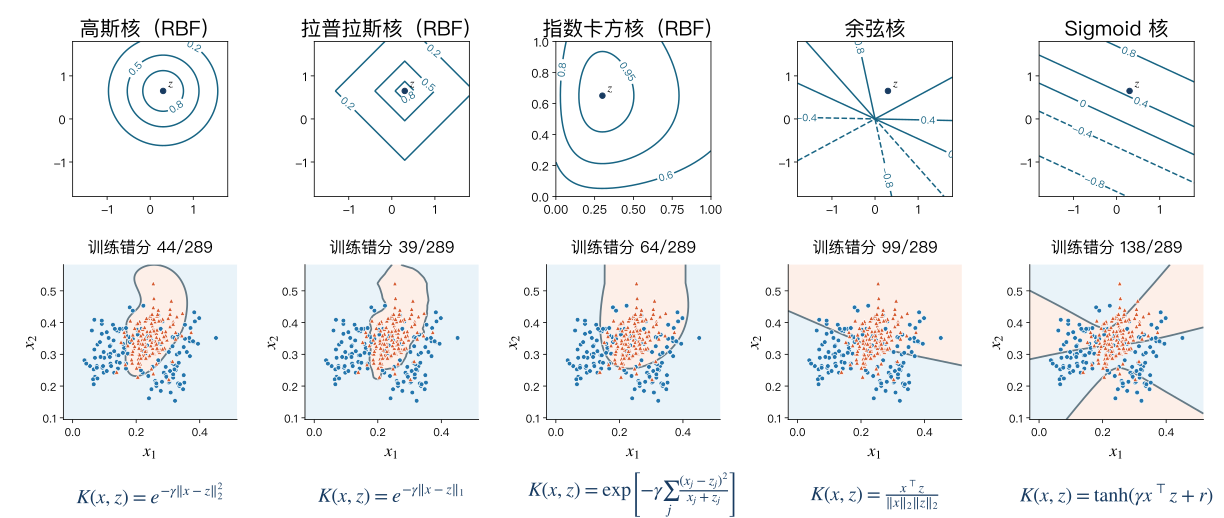

In [33]:
extra_kernels = [rbf_kernel, laplacian_kernel, chi2_kernel, cosine_similarity,
                 partial(sigmoid_kernel, coef0=0)]
rows = []
for name, kernel in zip(['高斯', '拉普拉斯', '指数卡方', '余弦', 'Sigmoid'], extra_kernels):
    scaler = MinMaxScaler(clip=True) if kernel is chi2_kernel else StandardScaler()
    configured_kernel = kernel if kernel is cosine_similarity else partial(kernel, gamma=1)
    model = make_pipeline(scaler, SVC(kernel=configured_kernel, C=1)).fit(Xd, yd)
    rows.append({'核函数': name, '训练错分': np.count_nonzero(model.predict(Xd) != yd)})
display(pd.DataFrame(rows))
show_slide_figure('l8-five-kernels.svg')

## 扩展阅读 B｜从感知机到 XOR 神经网络（p26）

隐藏层用两个 sigmoid 神经元。对相同输入和分别减去 0.5 和 1.5，再应用 sigmoid。输出分数 $f=h_1-h_2-0.22$，正分预测 1。代入四组输入，核对右图的分区。

<!-- # [ref:l8-xor-network] -->

,x1,x2,h1,h2,分数,预测
0,0.0,0.0,0.378,0.182,-0.025,0
1,0.0,1.0,0.622,0.378,0.025,1
2,1.0,0.0,0.622,0.378,0.025,1
3,1.0,1.0,0.818,0.622,-0.025,0


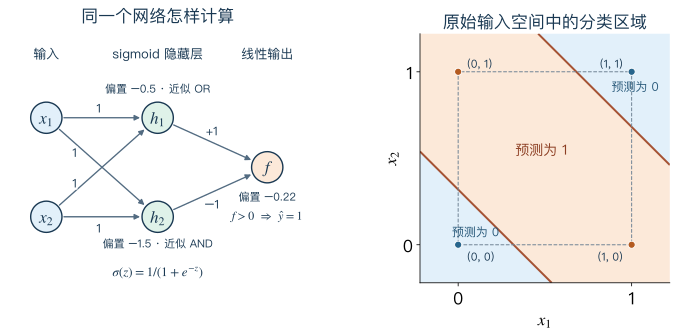

In [34]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

total = X_xor.sum(axis=1)
h1, h2 = sigmoid(total - .5), sigmoid(total - 1.5)
xor_score = h1 - h2 - .22
xor_prediction = (xor_score > 0).astype(int)
# 核对四组二进制输入的预测是否与 XOR 真值一致。
assert np.array_equal(xor_prediction, y_xor)
display(pd.DataFrame({'x1': X_xor[:, 0], 'x2': X_xor[:, 1],
                      'h1': h1, 'h2': h2, '分数': xor_score, '预测': xor_prediction}).round(3))
show_slide_figure('l8-xor-sigmoid-network.svg')
warnings.showwarning = original_showwarning
plot_output.cleanup()